# 03 — Option Surface Distributions

**Purpose:** characterize the 0DTE option-surface features before any of them enter the regime feature contract, and test the three surface questions raised by the project audit:

| Audit item | Question tested here |
|---|---|
| **A2** | Does the fixed log-moneyness grid ($k = \pm2.5\%, \pm5\%$) mean the same thing at different times to expiry and across assets? Would a standardized-moneyness grid $z = k / (\sigma_{ATM}\sqrt{\tau})$ be more stationary? |
| **B2** | How much of the "preferred" surface is Deribit's mark model rather than market quotes, and do switches between the two sources create artificial jumps in surface changes? |
| **B1** | How many valid option snapshots are lost because surface eligibility requires the futures stream? |
| **B4** | Do features behave differently inside the 07:30–08:00 UTC settlement window? |

This notebook:

- opens `research.duckdb` **read-only**, in a **UTC** session;
- uses `time_series_feature_state` for the model-facing features and the long-form option views (`normalized_option_chain`, `smile_node_state`) for diagnostics the feature table cannot answer;
- builds a **standardized-moneyness prototype in memory only**. Nothing is written to the database.

It does **not**:

- impute, winsorize, or standardize anything;
- fit an SSVI or any arbitrage-free surface;
- change the production surface (if the evidence favours $z$-space, the change goes into `src/data_engineering/surfaces/` as a separate, reviewed step);
- define final time-to-expiry bins. The buckets below are exploratory.

> Time to expiry and time of day are the same clock for a daily 0DTE (expiry 08:00 UTC). Every "TTE effect" in this notebook is also an intraday-seasonality effect.

## 1. Environment and read-only connection

In [20]:
from pathlib import Path
import os
import math
import time
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

pd.set_option("display.max_columns", 220)
pd.set_option("display.max_rows", 220)
pd.set_option("display.width", 200)

load_dotenv()

data_root_env = os.getenv("DERIBIT_DATA_ROOT")
if not data_root_env:
    raise RuntimeError("DERIBIT_DATA_ROOT is not defined in the environment/.env file.")

DATA_ROOT = Path(data_root_env).expanduser().resolve()
DB_PATH = DATA_ROOT / "database" / "research.duckdb"
if not DB_PATH.exists():
    raise FileNotFoundError(f"Research database not found: {DB_PATH}")

con = duckdb.connect(str(DB_PATH), read_only=True)
con.execute("SET TimeZone = 'UTC'")

print(f"Research DB:        {DB_PATH}")
print("Connection mode:    read-only")
print("Session time zone:", con.execute("SELECT current_setting('TimeZone')").fetchone()[0])


def q(sql, label):
    """Run a read-only query and report its size and runtime."""
    started = time.perf_counter()
    df = con.execute(sql).df()
    print(f"[{label}] {len(df):,} rows in {time.perf_counter() - started:,.1f}s")
    return df


def relation_columns(name):
    return set(con.execute(f"DESCRIBE SELECT * FROM {name}").df()["column_name"])

Research DB:        D:\MarketData\Deribit\database\research.duckdb
Connection mode:    read-only
Session time zone: UTC


## 2. Load the model-facing option features

Feature families:

- **Fixed-$k$ levels:** ATM IV, symmetric IV differences ("skew") and curvature at $k=\pm2.5\%$ and $\pm5\%$, local skew slopes.
- **Delta levels:** 25Δ/10Δ put and call IV, risk reversals (RR) and butterflies (BF).
- **Dynamics:** 5m / 15m / 1h changes, blocked across the 08:00 session boundary by the pipeline.
- **Quality metadata:** quality tier, usability flags, interpolation spans, eligible rows and option spreads.

IV units are detected from the data and printed; the standardized-moneyness calculation converts to decimals.

In [21]:
features = con.execute(
    "SELECT * FROM time_series_feature_state ORDER BY state_time, underlying"
).df()
features["state_time"] = pd.to_datetime(features["state_time"], utc=True)

OPTION_LEVEL = [
    "option_iv_atm_forward",
    "option_skew_025", "option_skew_050",
    "option_curvature_025", "option_curvature_050",
    "option_local_skew_slope_025", "option_local_skew_slope_050",
    "iv_put_25d", "iv_call_25d", "rr_25d", "bf_25d",
    "iv_put_10d", "iv_call_10d", "rr_10d", "bf_10d",
]
OPTION_DYNAMIC = [
    "atm_iv_change_5m", "atm_iv_change_15m", "atm_iv_change_1h",
    "skew_025_change_5m", "skew_025_change_15m", "skew_025_change_1h",
    "curvature_025_change_5m", "curvature_025_change_15m", "curvature_025_change_1h",
    "skew_050_change_5m", "rr_25d_change_5m", "bf_25d_change_5m",
]
OPTION_QUALITY = [
    "core_smile_quality_tier", "core_smile_tight", "core_smile_usable",
    "wing_050_usable", "full_grid_usable",
    "core_max_interpolation_span", "wing_050_max_interpolation_span",
    "full_grid_max_interpolation_span",
    "delta_25d_smile_available", "full_delta_smile_available",
    "max_delta_interpolation_span", "median_delta_interpolation_span",
    "option_base_eligible_rows", "option_two_sided_eligible_rows",
    "option_median_two_sided_spread_bps", "option_p90_two_sided_spread_bps",
]

for name, cols in [("level", OPTION_LEVEL), ("dynamic", OPTION_DYNAMIC), ("quality", OPTION_QUALITY)]:
    missing = [c for c in cols if c not in features.columns]
    print(f"{name:<8} {len(cols) - len(missing):>2} / {len(cols)} available" + (f" | missing: {missing}" if missing else ""))

OPTION_LEVEL = [c for c in OPTION_LEVEL if c in features.columns]
OPTION_DYNAMIC = [c for c in OPTION_DYNAMIC if c in features.columns]

# IV units: Deribit publishes IV in percent. Detect rather than assume.
atm_median = pd.to_numeric(features["option_iv_atm_forward"], errors="coerce").median()
IV_TO_DECIMAL = 0.01 if atm_median > 3 else 1.0
print(f"\nMedian ATM IV: {atm_median:.4g} -> IV unit = {'percent' if IV_TO_DECIMAL == 0.01 else 'decimal'}")

MINUTES_PER_YEAR = 365.0 * 24.0 * 60.0
features["tte_years"] = features["minutes_to_expiry"] / MINUTES_PER_YEAR
features["atm_sigma_sqrt_t"] = (
    pd.to_numeric(features["option_iv_atm_forward"], errors="coerce") * IV_TO_DECIMAL
    * np.sqrt(features["tte_years"])
)

# Exploratory buckets only; they are not model boundaries.
TTE_EDGES = [0, 30, 60, 180, 360, 720, 1080, 1440]
TTE_LABELS = ["≤30m (settle)", "30m–1h", "1–3h", "3–6h", "6–12h", "12–18h", "18–24h"]
features["tte_bucket"] = pd.cut(features["minutes_to_expiry"], bins=TTE_EDGES, labels=TTE_LABELS, right=True)
features["in_settlement_window"] = features["minutes_to_expiry"] <= 30

ASSETS = sorted(features["underlying"].dropna().unique())
print(f"Rows: {len(features):,} | assets: {ASSETS}")
print(f"States: {features['state_time'].min()} → {features['state_time'].max()}")

level    15 / 15 available
dynamic  12 / 12 available
quality  16 / 16 available

Median ATM IV: 45.43 -> IV unit = percent
Rows: 32,256 | assets: ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP']
States: 2026-09-19 08:00:00+00:00 → 2026-10-05 07:55:00+00:00


In [22]:
CENTRAL_LOWER_Q, CENTRAL_UPPER_Q = 0.005, 0.995
TAIL_QS = [0.001, 0.01, 0.05, 0.50, 0.95, 0.99, 0.999]


def clean_numeric(df, column):
    return pd.to_numeric(df[column], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()


def feature_summary(df, columns, group_col=None):
    rows = []
    iterator = [("ALL", df)] if group_col is None else df.groupby(group_col, dropna=False, observed=True)
    for group_name, group in iterator:
        for col in columns:
            if col not in group.columns:
                continue
            s = clean_numeric(group, col)
            if s.empty:
                continue
            qv = s.quantile(TAIL_QS)
            rows.append({
                "group": group_name, "feature": col, "n": len(s),
                "missing_pct": 100.0 * (len(group) - len(s)) / max(len(group), 1),
                "mean": s.mean(), "std": s.std(), "skew": s.skew(), "excess_kurtosis": s.kurt(),
                "min": s.min(), "q001": qv.loc[0.001], "q01": qv.loc[0.01], "q05": qv.loc[0.05],
                "median": qv.loc[0.50], "q95": qv.loc[0.95], "q99": qv.loc[0.99], "q999": qv.loc[0.999],
                "max": s.max(),
            })
    return pd.DataFrame(rows)


def plot_asset_histograms(df, column, bins=60):
    ncols = 2
    nrows = math.ceil(len(ASSETS) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.4 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, asset in zip(axes, ASSETS):
        s = clean_numeric(df[df["underlying"] == asset], column)
        if s.empty:
            ax.text(0.5, 0.5, "No observations", ha="center", va="center")
        else:
            lo, hi = s.quantile(CENTRAL_LOWER_Q), s.quantile(CENTRAL_UPPER_Q)
            ax.hist(s[(s >= lo) & (s <= hi)], bins=bins)
        ax.set_title(str(asset))
    for ax in axes[len(ASSETS):]:
        ax.axis("off")
    fig.suptitle(f"{column} — per-asset central 99%", y=1.01)
    plt.tight_layout()
    plt.show()


def as_bool(s):
    """Nullable/boolean-like column -> plain bool (missing = False)."""
    if s.dtype == bool:
        return s
    mapped = s.map(lambda v: str(v).strip().lower() in ("true", "1", "1.0"))
    return mapped.astype(bool)


def median_by_tte(df, column, assets=None):
    """Median of a feature at each minutes_to_expiry, per asset."""
    assets = assets or ASSETS
    out = (
        df[df["underlying"].isin(assets)]
        .assign(_v=lambda d: pd.to_numeric(d[column], errors="coerce"))
        .groupby(["underlying", "minutes_to_expiry"])["_v"]
        .median()
        .unstack("underlying")
        .sort_index(ascending=False)
    )
    return out


def plot_median_by_tte(df, columns, title, logy=False):
    fig, axes = plt.subplots(1, len(columns), figsize=(6.5 * len(columns), 4.6), squeeze=False)
    for ax, col in zip(axes[0], columns):
        m = median_by_tte(df, col)
        for asset in m.columns:
            ax.plot(m.index / 60.0, m[asset], linewidth=1.2, label=str(asset))
        ax.invert_xaxis()
        ax.set_xlabel("hours to expiry")
        ax.set_title(col)
        if logy:
            ax.set_yscale("log")
    axes[0][0].legend(fontsize=8)
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


def eta_squared(df, column, group_col="tte_bucket"):
    """Share of a feature's variance explained by bucket medians (within one asset).

    0 means the clock explains nothing; 1 means the feature is a deterministic
    function of the clock bucket.
    """
    d = df[[column, group_col]].copy()
    d[column] = pd.to_numeric(d[column], errors="coerce")
    d = d.dropna()
    if len(d) < 50 or d[column].var() == 0:
        return np.nan
    group_mean = d.groupby(group_col, observed=True)[column].transform("mean")
    return float(((group_mean - d[column].mean()) ** 2).sum() / ((d[column] - d[column].mean()) ** 2).sum())


def within_session_acf(df, column, max_lag=24):
    """ACF on the exact 5-minute grid, never crossing a session boundary."""
    rows = []
    for asset, g in df.groupby("underlying"):
        g = g.sort_values("state_time")
        x = pd.to_numeric(g[column], errors="coerce")
        for lag in range(1, max_lag + 1):
            lx = x.shift(lag)
            ok = (
                x.notna() & lx.notna()
                & ((g["state_time"] - g["state_time"].shift(lag)) == pd.Timedelta(minutes=5 * lag))
                & (g["session_id"] == g["session_id"].shift(lag))
            )
            rows.append({
                "underlying": asset, "feature": column, "lag_minutes": 5 * lag,
                "n_pairs": int(ok.sum()),
                "acf": x[ok].corr(lx[ok]) if ok.sum() >= 20 else np.nan,
            })
    return pd.DataFrame(rows)

# Part A — Coverage

## 3. Option snapshots lost to the futures gate (audit B1)

Surface eligibility in `option_normalization.py` requires `state_research_ready`, which requires a complete **futures** stream. The option forward is built from the option chain itself, so the surface does not need the futures.

`lost_to_futures_gate` counts states with a valid option snapshot (`option_snapshot_ready`) but no surface because the futures side was not ready. These states include every session before the futures collector started and every futures reconnect.

In [23]:
cms_cols = relation_columns("canonical_market_state")
needed = {"option_snapshot_ready", "state_research_ready", "price_features_ready"}
if needed.issubset(cms_cols):
    gate = q(
        """
        SELECT
            underlying,
            expiry_date,
            COUNT(*) AS states,
            SUM(CASE WHEN option_snapshot_ready THEN 1 ELSE 0 END) AS option_ready,
            SUM(CASE WHEN state_research_ready THEN 1 ELSE 0 END) AS research_ready,
            SUM(CASE WHEN option_snapshot_ready AND NOT COALESCE(state_research_ready, FALSE)
                     THEN 1 ELSE 0 END) AS lost_to_futures_gate,
            SUM(CASE WHEN option_snapshot_ready AND NOT COALESCE(price_features_ready, FALSE)
                     THEN 1 ELSE 0 END) AS option_ok_futures_not_ready
        FROM canonical_market_state
        GROUP BY 1, 2
        ORDER BY 2, 1
        """,
        "futures-gate loss",
    )
    by_asset = gate.groupby("underlying")[["states", "option_ready", "research_ready", "lost_to_futures_gate"]].sum()
    by_asset["lost_pct_of_option_ready"] = 100 * by_asset["lost_to_futures_gate"] / by_asset["option_ready"]
    display(by_asset.round(2))
    display(
        gate.pivot_table(index="expiry_date", columns="underlying", values="lost_to_futures_gate", aggfunc="sum")
    )
else:
    print(f"canonical_market_state lacks {needed - cms_cols}; section skipped.")
    gate = pd.DataFrame()

[futures-gate loss] 112 rows in 0.7s


,states,option_ready,research_ready,lost_to_futures_gate,lost_pct_of_option_ready
underlying,,,,,
AVAX,4608,4239.0,3934.0,305.0,7.2
BTC,4608,4239.0,3934.0,305.0,7.2
ETH,4608,4239.0,3934.0,305.0,7.2
HYPE,4608,4239.0,3934.0,305.0,7.2
SOL,4608,4239.0,3934.0,305.0,7.2
TRX,4608,4239.0,3934.0,305.0,7.2
XRP,4608,4239.0,3934.0,305.0,7.2


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
expiry_date,,,,,,,
2026-09-20,15.0,15.0,15.0,15.0,15.0,15.0,15.0
2026-09-21,204.0,204.0,204.0,204.0,204.0,204.0,204.0
2026-09-22,33.0,33.0,33.0,33.0,33.0,33.0,33.0
2026-09-23,6.0,6.0,6.0,6.0,6.0,6.0,6.0
2026-09-24,3.0,3.0,3.0,3.0,3.0,3.0,3.0
2026-09-25,5.0,5.0,5.0,5.0,5.0,5.0,5.0
2026-09-26,6.0,6.0,6.0,6.0,6.0,6.0,6.0
2026-09-27,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-09-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Surface availability through the session

Which surface representations exist at each time to expiry? The fixed-$k$ core needs strikes bracketing $k=0, \pm2.5\%$; the delta smile needs options with $|\Delta|$ around 0.25 and 0.10, which disappear near expiry as deltas collapse to 0 or 1.

Share of states with a primary option family where each representation is available (%):


core_smile_usable  core_smile_tight  wing_050_usable  full_grid_usable  delta_25d_smile_available  full_delta_smile_available
underlying tte_bucket                                                                                                                                  
AVAX       ≤30m (settle)              100.0             100.0            100.0             100.0                        2.2                         2.2
           30m–1h                     100.0             100.0            100.0             100.0                       16.7                        16.7
           1–3h                       100.0             100.0            100.0              96.4                       51.8                        51.8
           3–6h                       100.0             100.0            100.0              97.4                       91.1                        91.1
           6–12h                       99.9              99.9             99.9              95.8                       96.9                        96.9
           12–18h                     100.0             100.0            100.0              95.8                      100.0                       100.0
           18–24h                      99.0              99.0             99.0              97.6                       99.0                        99.0
BTC        ≤30m (settle)              100.0             100.0            100.0              78.9                        0.0                         0.0
           30m–1h                     100.0             100.0            100.0              75.6                        0.0                         0.0
           1–3h                       100.0             100.0            100.0              73.5                        6.4                         6.4
           3–6h                       100.0             100.0             98.0              75.7                       27.2                        27.2
           6–12h                       99.9              99.9             93.4              76.1                       63.1                        63.1
           12–18h                     100.0             100.0             93.8              70.2                       84.8                        84.8
           18–24h                      99.0              99.0             99.0              76.4                       90.7                        90.7
ETH        ≤30m (settle)              100.0             100.0            100.0              80.0                        0.0                         0.0
           30m–1h                     100.0             100.0            100.0              80.0                        2.2                         2.2
           1–3h                       100.0             100.0            100.0              79.9                       12.3                        12.3
           3–6h                       100.0             100.0            100.0              80.0                       37.6                        37.6
           6–12h                       99.9              99.9             99.9              80.5                       69.5                        69.5
           12–18h                     100.0             100.0            100.0              81.7                       89.3                        89.3
           18–24h                      99.0              99.0             99.0              87.0                       91.9                        91.9
HYPE       ≤30m (settle)              100.0             100.0            100.0              96.7                        0.0                         0.0
           30m–1h                     100.0             100.0            100.0             100.0                        1.1                         1.1
           1–3h                       100.0             100.0            100.0             100.0                       13.4                        13.4
           3–6h                       100.0             100.0            1

core_smile_quality_tier,A,D
underlying,,
AVAX,99.7,0.3
BTC,99.7,0.3
ETH,99.7,0.3
HYPE,99.7,0.3
SOL,99.7,0.3
TRX,99.7,0.3
XRP,96.9,3.1


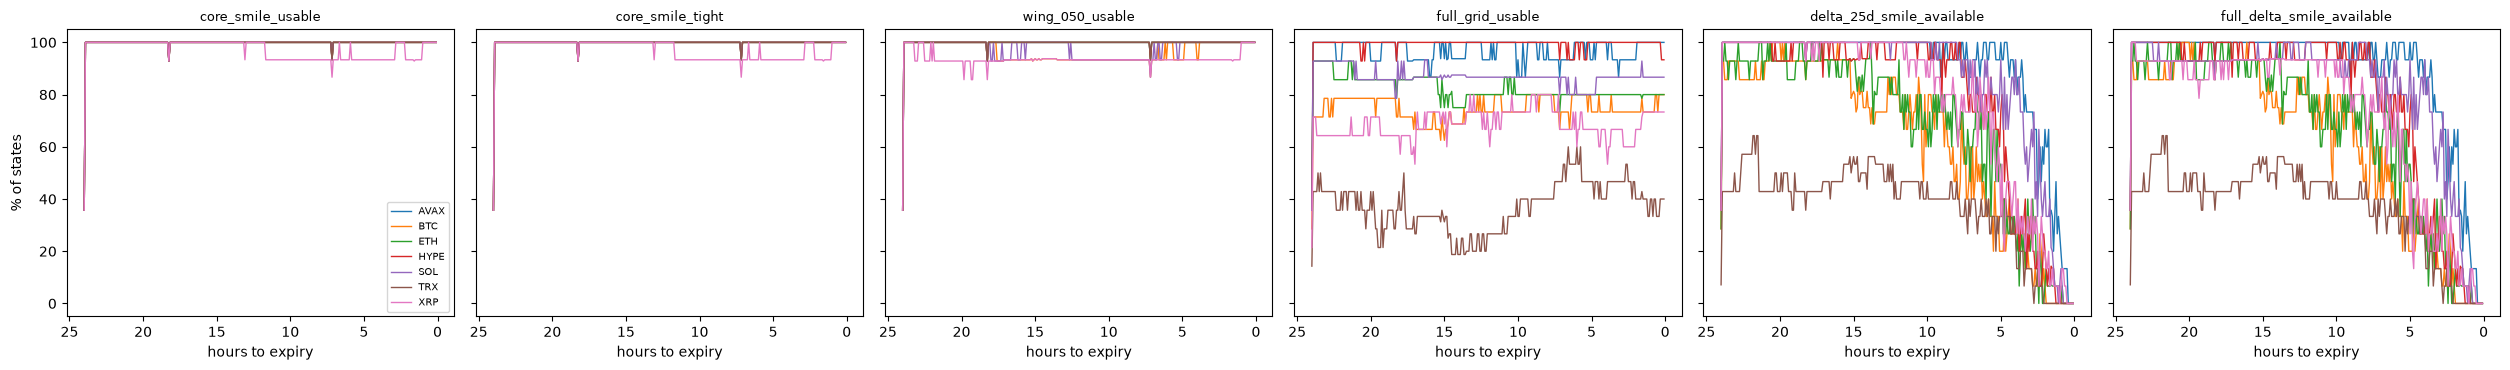

In [24]:
avail_cols = [c for c in [
    "core_smile_usable", "core_smile_tight", "wing_050_usable", "full_grid_usable",
    "delta_25d_smile_available", "full_delta_smile_available",
] if c in features.columns]

opt_rows = features[features["primary_option_family_id"].notna()] if "primary_option_family_id" in features.columns else features
availability = (
    opt_rows.assign(**{c: as_bool(opt_rows[c]) for c in avail_cols})
    .groupby(["underlying", "tte_bucket"], observed=True)[avail_cols]
    .mean()
    .mul(100)
    .round(1)
)
print("Share of states with a primary option family where each representation is available (%):")
display(availability)

if "core_smile_quality_tier" in features.columns:
    tiers = (
        opt_rows.groupby(["underlying", "core_smile_quality_tier"]).size()
        .unstack(fill_value=0)
    )
    display(tiers.div(tiers.sum(axis=1), axis=0).mul(100).round(1))

fig, axes = plt.subplots(1, len(avail_cols), figsize=(4.2 * len(avail_cols), 3.8), sharey=True)
for ax, col in zip(np.atleast_1d(axes), avail_cols):
    m = (
        opt_rows.assign(_v=as_bool(opt_rows[col]).astype(float))
        .groupby(["minutes_to_expiry", "underlying"])["_v"].mean().unstack()
        .sort_index(ascending=False)
    )
    for asset in m.columns:
        ax.plot(m.index / 60, 100 * m[asset], linewidth=1, label=asset)
    ax.invert_xaxis()
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("hours to expiry")
np.atleast_1d(axes)[0].set_ylabel("% of states")
np.atleast_1d(axes)[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

# Part B — Level Distributions

## 5. Pooled and per-asset distributions

ATM IV levels differ several-fold across assets, so pooled quantiles mainly describe the asset mix. The per-asset table is the relevant one.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,ALL,option_iv_atm_forward,29658,8.054315,48.438705,23.908942,0.778196,3.614682,8.654510,10.831439,13.257084,17.961103,45.429047,90.030088,110.186861,128.732534,457.556512
1,ALL,option_skew_025,29554,8.376736,3.246343,9.415997,8.001454,243.929924,-56.083210,-48.055966,-16.915743,-8.676438,3.027663,15.752861,25.092193,65.624562,379.486618
2,ALL,option_skew_050,29170,9.567212,4.433685,12.277643,0.994434,12.205314,-76.863050,-53.748478,-28.720516,-13.243118,4.108996,22.644426,37.554254,79.056657,140.380268
3,ALL,option_curvature_025,29554,8.376736,9.114080,8.275550,-3.103424,301.086136,-416.786227,-14.035937,-1.598437,0.742255,7.740281,22.176314,33.991325,52.939919,198.451851
4,ALL,option_curvature_050,29170,9.567212,20.258454,10.473068,-2.617650,129.377742,-405.665181,-4.653706,2.151357,6.530532,19.300139,36.856743,49.832857,69.938108,90.968362
5,ALL,option_local_skew_slope_025,29554,8.376736,64.926852,188.319949,8.001454,243.929924,-1121.664206,-961.119314,-338.314864,-173.528754,60.553261,315.057215,501.843861,1312.491230,7589.732356
6,ALL,option_local_skew_slope_050,29170,9.567212,44.336852,122.776425,0.994434,12.205314,-768.630504,-537.484783,-287.205161,-132.431175,41.089959,226.444264,375.542540,790.566568,1403.802684
7,ALL,iv_put_25d,24371,24.445064,51.617214,23.430570,0.751972,5.755451,10.949474,11.902380,13.920414,19.903838,50.878778,92.059980,112.023784,128.237984,512.549982
8,ALL,iv_call_25d,24938,22.687252,54.538058,25.157452,0.487922,-0.186674,12.329855,13.114151,15.545346,20.637848,54.091695,98.462649,120.601050,136.537228,244.626770
9,ALL,rr_25d,21294,33.984375,3.582503,6.202505,-20.002202,1706.390422,-474.442084,-16.296422,-7.155252,-3.588731,3.089470,12.476682,17.186395,27.258719,198.183963


,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,option_iv_atm_forward,4239,8.007812,78.297186,19.878023,0.136332,-0.357815,37.049039,38.023527,38.933650,43.389280,79.544286,113.352372,126.333320,131.259176,134.990000
1,AVAX,option_skew_025,4239,8.007812,4.775876,7.565173,1.162540,14.649788,-44.400912,-36.446813,-18.584570,-4.234030,4.431181,15.529161,30.146154,63.931765,66.479585
2,AVAX,option_skew_050,4239,8.007812,8.278523,16.366418,2.157714,21.496226,-76.863050,-70.740976,-40.278849,-9.850288,7.096668,25.611458,60.160749,139.620000,140.380268
3,AVAX,option_curvature_025,4239,8.007812,5.147678,5.664384,3.123864,15.778068,-25.251217,-8.422271,-0.764204,0.735058,3.625540,15.401878,28.814038,49.442602,52.235120
4,AVAX,option_curvature_050,4239,8.007812,15.607484,10.508988,2.612116,10.623882,-18.175527,-2.420966,1.934746,5.148547,13.641403,33.422559,59.720544,89.189923,90.968362
5,AVAX,option_local_skew_slope_025,4239,8.007812,95.517527,151.303469,1.162540,14.649788,-888.018232,-728.936266,-371.691396,-84.680601,88.623614,310.583230,602.923086,1278.635296,1329.591705
6,AVAX,option_local_skew_slope_050,4239,8.007812,82.785226,163.664177,2.157714,21.496226,-768.630504,-707.409762,-402.788487,-98.502882,70.966677,256.114584,601.607493,1396.200000,1403.802684
7,AVAX,iv_put_25d,3965,13.953993,78.790339,19.783524,0.017820,-0.567038,37.265044,37.501838,38.950775,43.373812,80.029370,113.213730,122.668371,128.227947,131.211141
8,AVAX,iv_call_25d,4016,12.847222,83.517377,21.198705,0.161524,-0.335597,38.205691,39.272172,41.456932,46.513571,84.770069,122.282033,133.690249,138.828461,147.906102
9,AVAX,rr_25d,3822,17.057292,5.010079,4.072848,0.684131,6.130156,-19.501503,-14.568296,-4.261025,-0.743254,4.634846,11.632319,15.502043,29.132392,31.173967


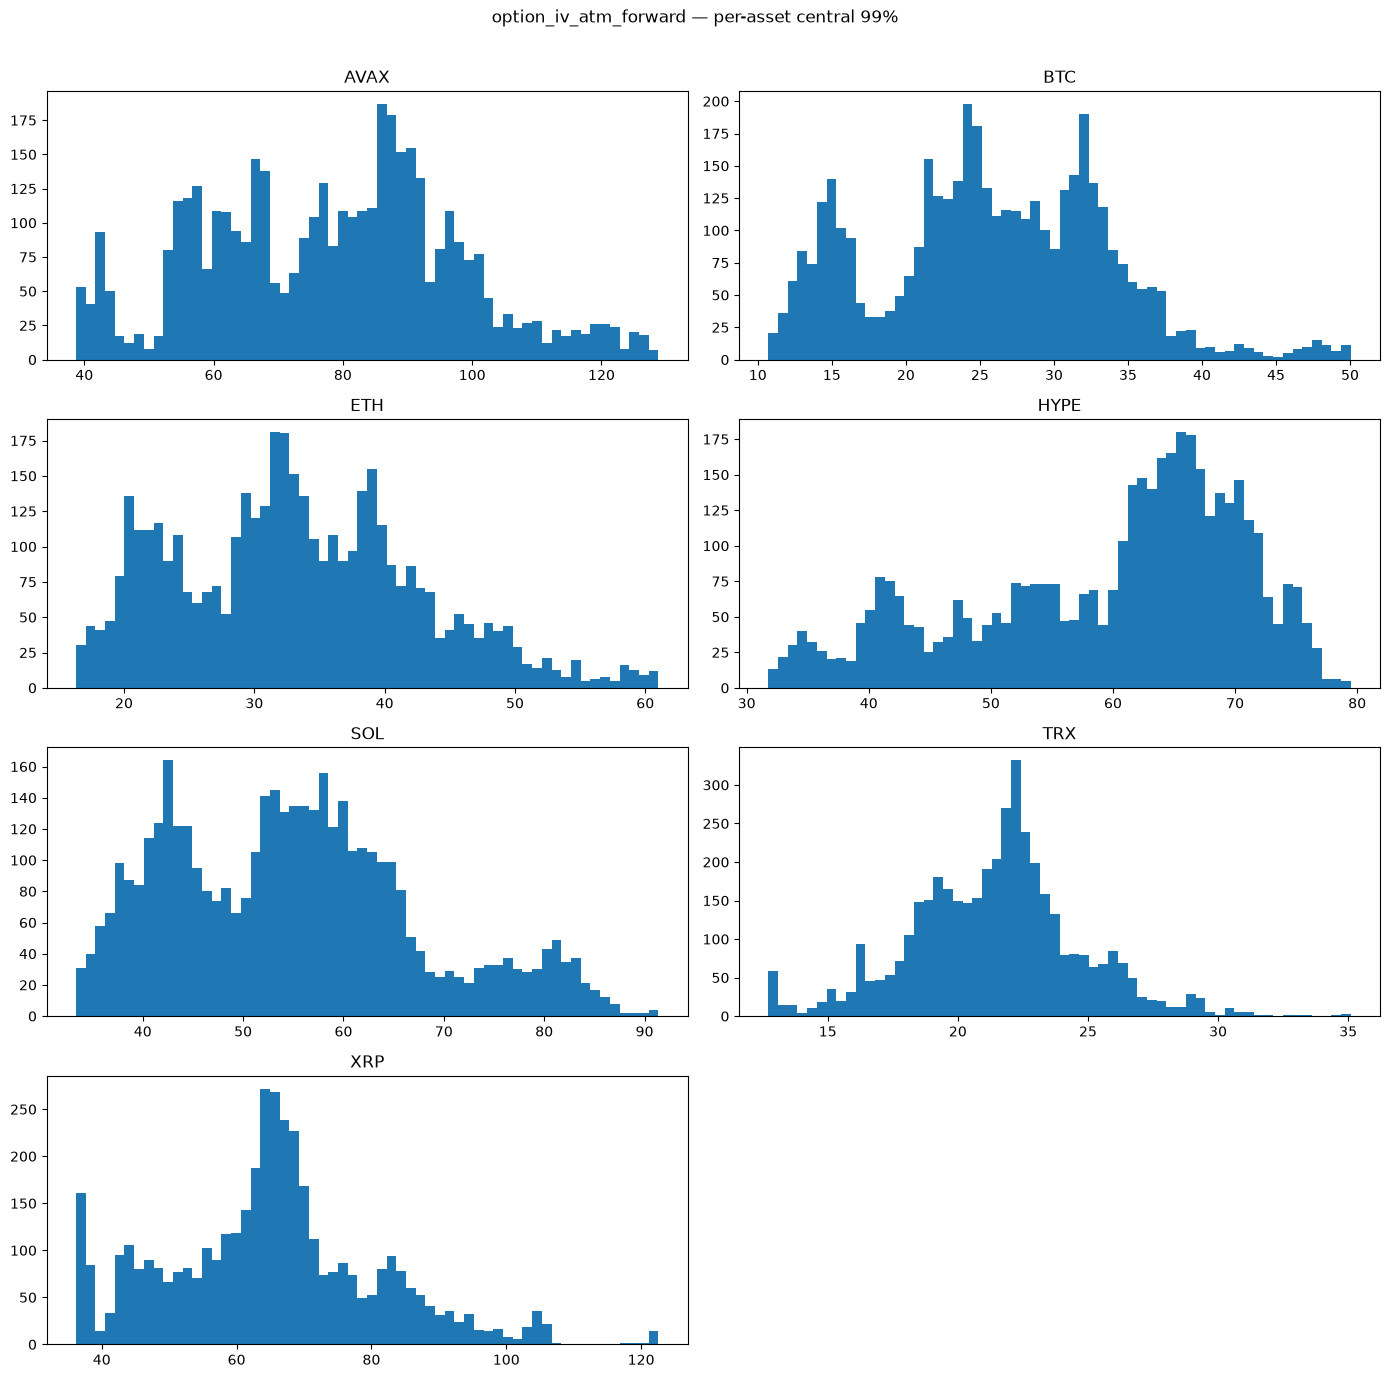

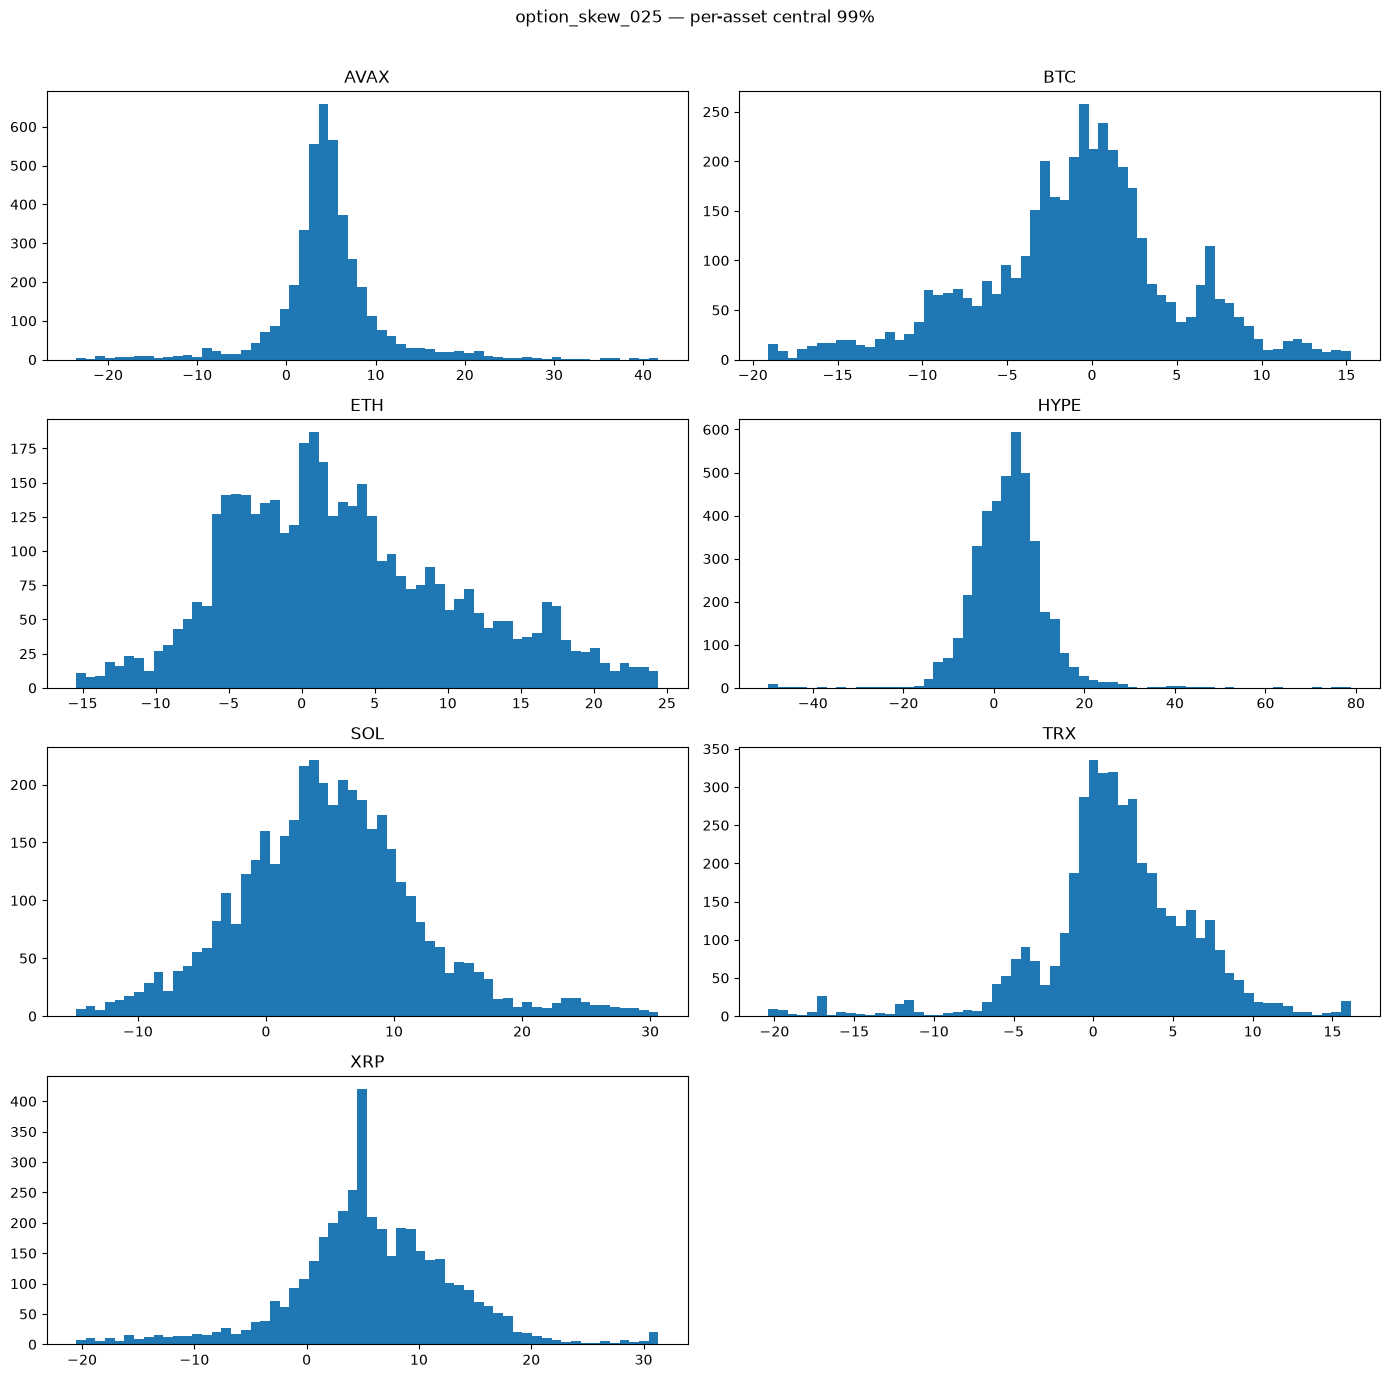

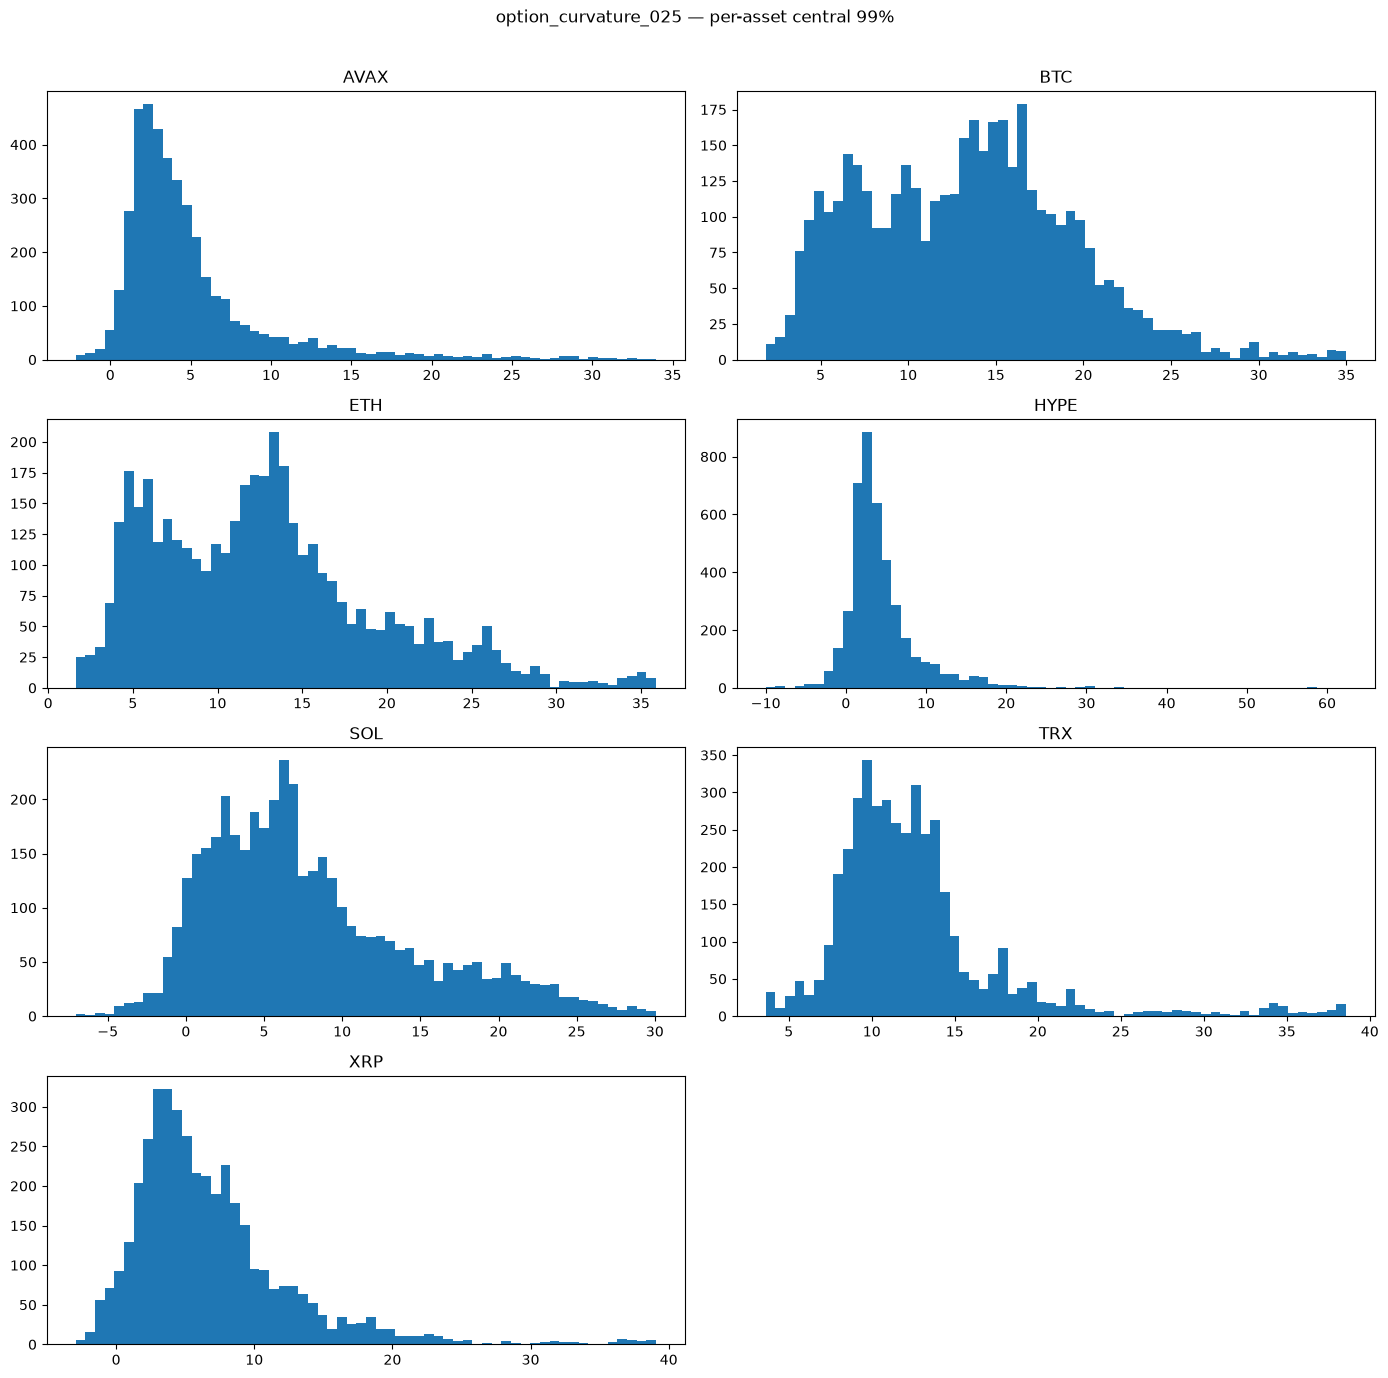

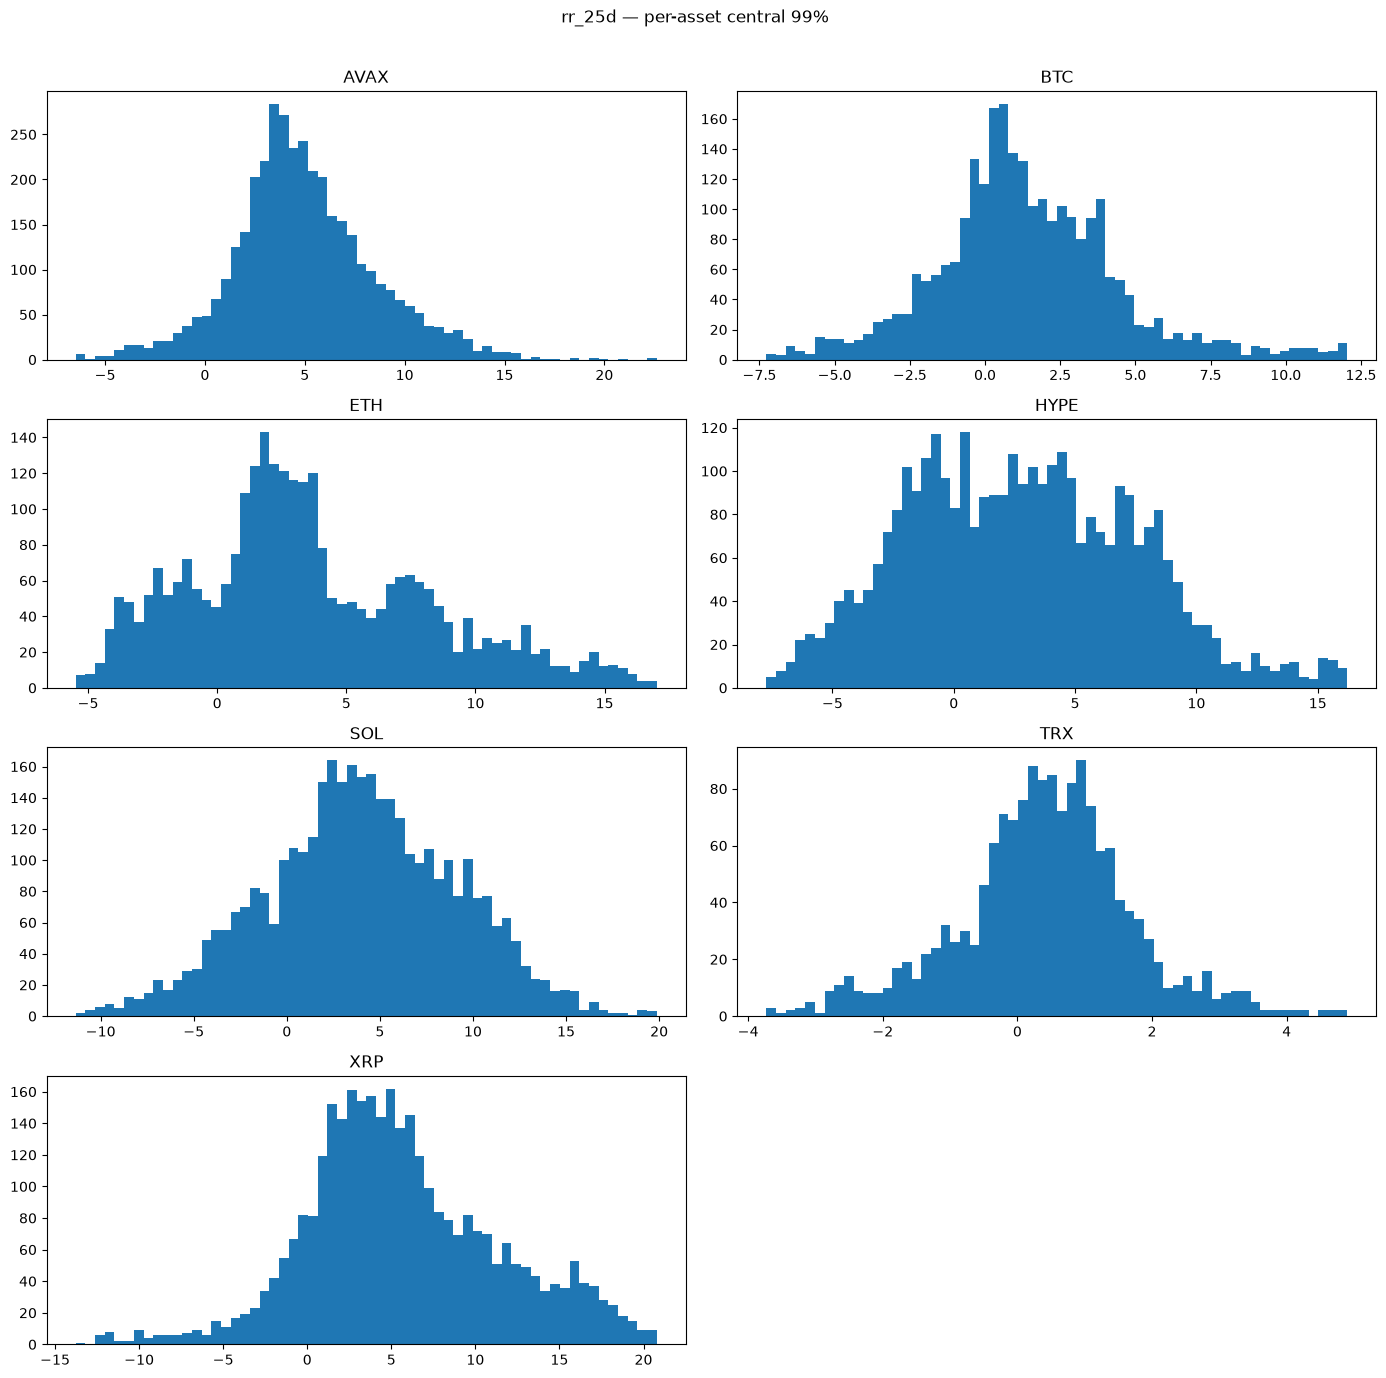

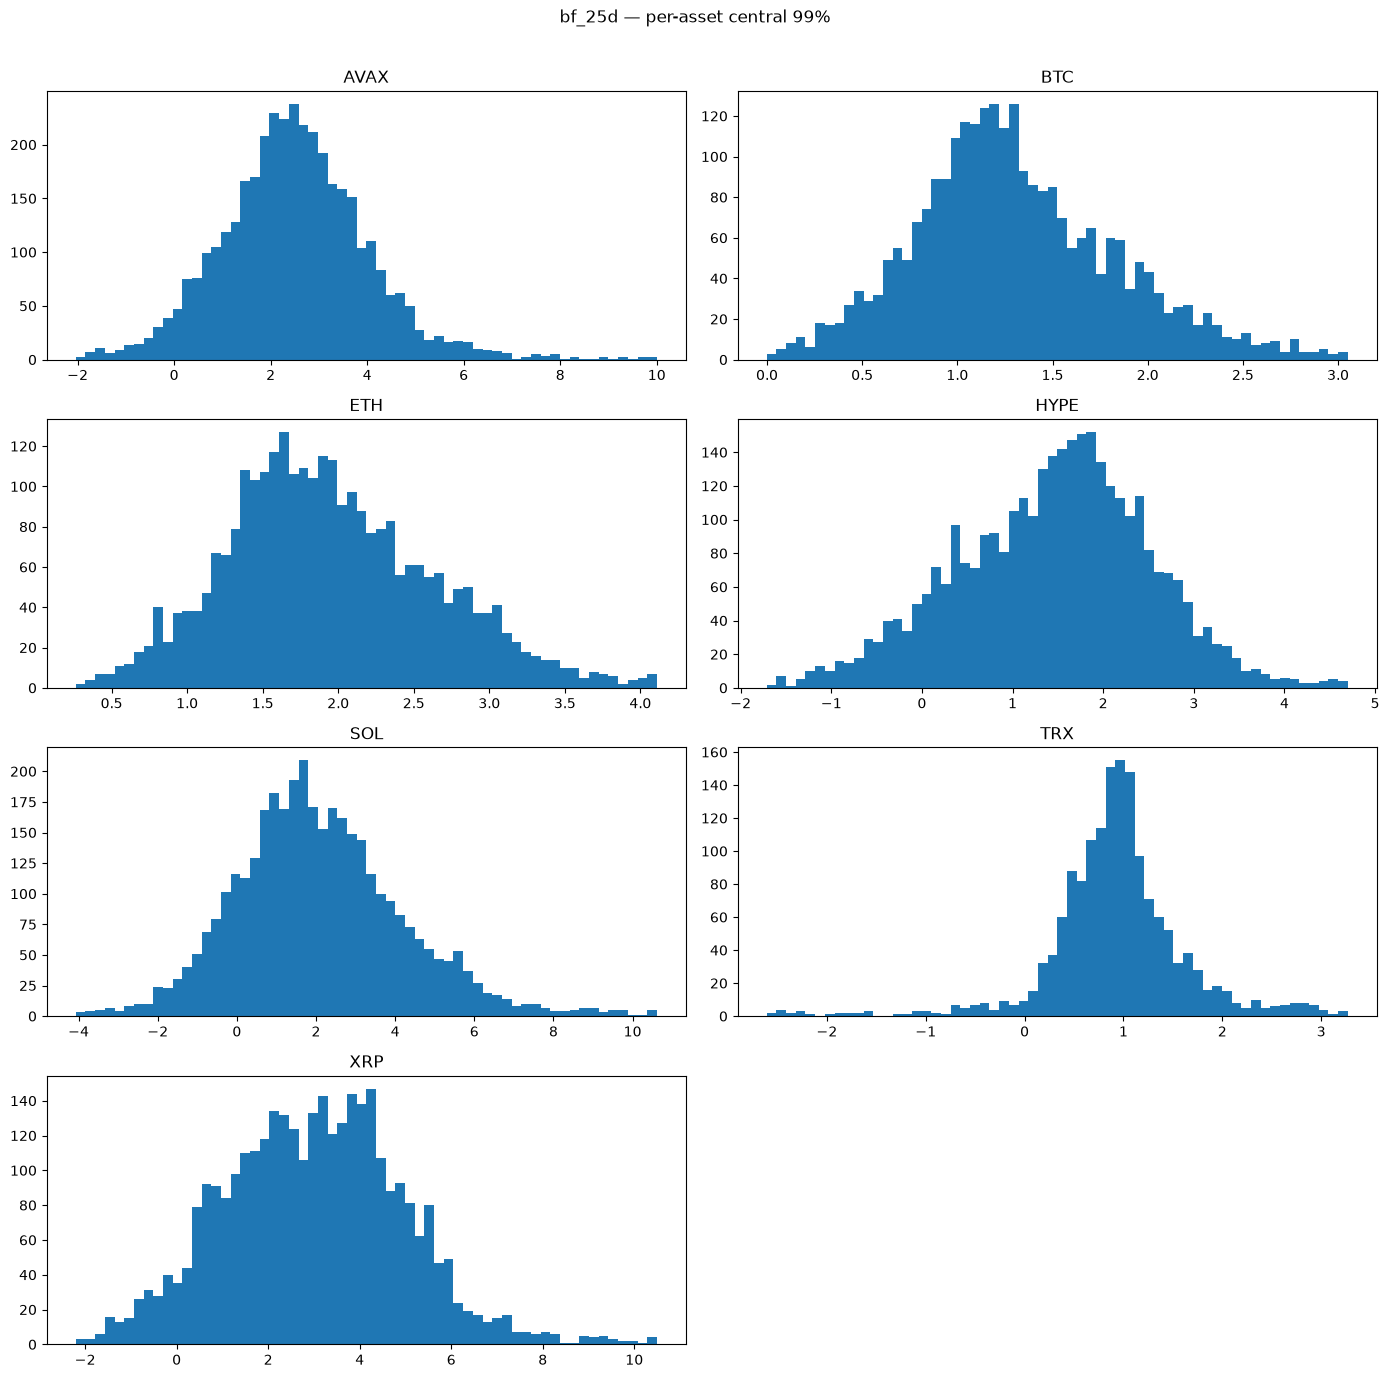

In [25]:
level_summary = feature_summary(features, OPTION_LEVEL)
level_by_asset = feature_summary(features, OPTION_LEVEL, group_col="underlying")
display(level_summary)
display(level_by_asset)

for col in ["option_iv_atm_forward", "option_skew_025", "option_curvature_025", "rr_25d", "bf_25d"]:
    if col in features.columns:
        plot_asset_histograms(features, col)

# Part C — Does Fixed Log-Moneyness Mean the Same Thing All Session? (audit A2)

## 6. The ±2.5% node in units of expected move

A 0DTE option's one-standard-deviation move to expiry is $\sigma_{ATM}\sqrt{\tau}$, which shrinks through the session. The fixed node $k = \pm 2.5\%$ sits at

$$
z_{2.5\%} = \frac{0.025}{\sigma_{ATM}\,\sqrt{\tau}}
$$

standard deviations from the forward. If $z_{2.5\%}$ moves from about 1 in the morning to 5–10 near expiry, `option_skew_025` measures near-ATM skew early in the session and far-wing skew late in it. Its time-of-day profile is then mostly mechanical.

Median z of the ±2.5% node, by asset and time to expiry:


tte_bucket,≤30m (settle),30m–1h,1–3h,3–6h,6–12h,12–18h,18–24h
underlying,,,,,,,
AVAX,5.72,3.54,2.29,1.51,1.07,0.74,0.56
BTC,18.22,10.36,6.55,4.25,3.37,2.38,1.63
ETH,14.13,8.34,5.21,3.49,2.65,1.91,1.28
HYPE,7.31,4.16,2.66,1.96,1.33,0.99,0.75
SOL,7.65,4.41,3.03,2.15,1.56,1.11,0.83
TRX,19.62,11.53,7.05,5.02,3.90,2.89,2.29
XRP,7.16,4.18,2.58,1.80,1.30,0.92,0.73


Share of states where the ±2.5% node is more than 2, 3 or 5 expected moves away:


,states,beyond_2sd_pct,beyond_3sd_pct,beyond_5sd_pct
underlying,,,,
AVAX,4239,13.6,4.9,1.6
BTC,4239,77.4,50.3,20.6
ETH,4239,61.9,32.0,10.9
HYPE,4239,20.2,8.3,2.7
SOL,4239,24.4,9.6,2.8
TRX,4239,97.9,61.2,20.4
XRP,4224,17.4,7.2,2.4


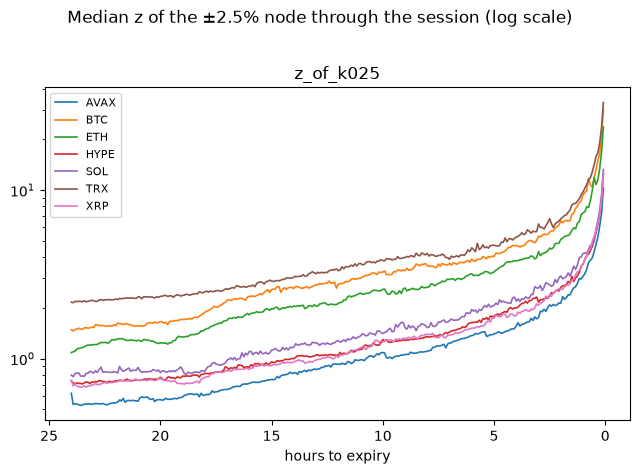

In [26]:
features["z_of_k025"] = 0.025 / features["atm_sigma_sqrt_t"]
features["z_of_k050"] = 0.050 / features["atm_sigma_sqrt_t"]

z_table = (
    features.groupby(["underlying", "tte_bucket"], observed=True)["z_of_k025"]
    .median()
    .unstack("tte_bucket")
    .round(2)
)
print("Median z of the ±2.5% node, by asset and time to expiry:")
display(z_table)

beyond = (
    features.dropna(subset=["z_of_k025"])
    .groupby("underlying")["z_of_k025"]
    .agg(
        states="count",
        beyond_2sd_pct=lambda s: 100 * (s > 2).mean(),
        beyond_3sd_pct=lambda s: 100 * (s > 3).mean(),
        beyond_5sd_pct=lambda s: 100 * (s > 5).mean(),
    )
    .round(1)
)
print("Share of states where the ±2.5% node is more than 2, 3 or 5 expected moves away:")
display(beyond)

plot_median_by_tte(features, ["z_of_k025"], "Median z of the ±2.5% node through the session (log scale)", logy=True)

## 7. Mechanical drift of fixed-$k$ features

If fixed-$k$ features were stationary through the session, their median would be flat in time to expiry. The plots and the $\eta^2$ table measure how much of each feature's variance the clock bucket explains, per asset:

$$
\eta^2 = \frac{\sum_t (\bar x_{b(t)} - \bar x)^2}{\sum_t (x_t - \bar x)^2}
$$

where $\bar x_{b(t)}$ is the mean of the feature in the time-to-expiry bucket of state $t$. A high $\eta^2$ means the feature mostly encodes the clock. Part D compares this with the standardized-moneyness prototype.

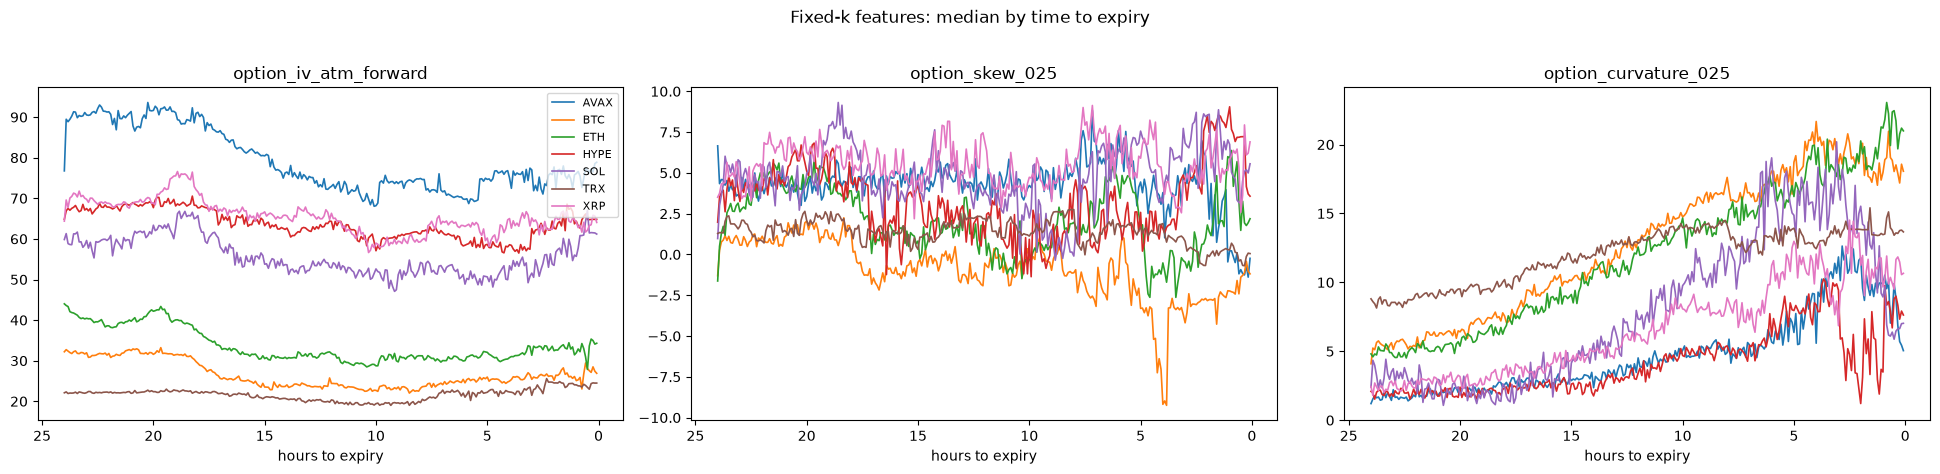

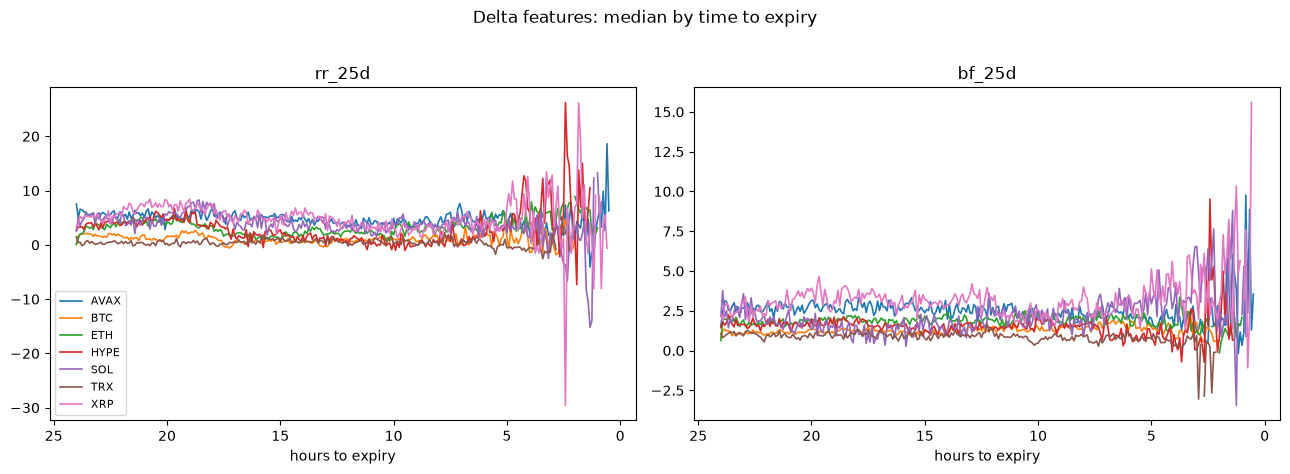

η² of the time-to-expiry bucket, per asset (fixed-k and delta features):


underlying,AVAX,BTC,ETH,HYPE,SOL,TRX,XRP
feature,,,,,,,
bf_10d,0.082,0.002,0.011,0.058,0.161,0.023,0.013
bf_25d,0.033,0.002,0.002,0.025,0.089,0.073,0.025
iv_call_10d,0.084,0.073,0.084,0.072,0.019,0.026,0.066
iv_call_25d,0.053,0.102,0.070,0.058,0.051,0.149,0.079
iv_put_10d,0.044,0.051,0.076,0.043,0.008,0.048,0.019
iv_put_25d,0.050,0.032,0.068,0.063,0.064,0.098,0.039
option_curvature_025,0.342,0.290,0.416,0.104,0.430,0.206,0.325
option_curvature_050,0.372,0.195,0.267,0.258,0.339,0.056,0.396
option_iv_atm_forward,0.048,0.054,0.076,0.060,0.069,0.114,0.051


In [27]:
plot_median_by_tte(
    features,
    [c for c in ["option_iv_atm_forward", "option_skew_025", "option_curvature_025"] if c in features.columns],
    "Fixed-k features: median by time to expiry",
)
plot_median_by_tte(
    features,
    [c for c in ["rr_25d", "bf_25d"] if c in features.columns],
    "Delta features: median by time to expiry",
)

eta_rows = []
for asset, g in features.groupby("underlying"):
    for col in [c for c in OPTION_LEVEL if c in g.columns]:
        eta_rows.append({"underlying": asset, "feature": col, "eta2_tte": eta_squared(g, col)})
eta_fixed = pd.DataFrame(eta_rows).pivot(index="feature", columns="underlying", values="eta2_tte")
print("η² of the time-to-expiry bucket, per asset (fixed-k and delta features):")
display(eta_fixed.round(3))

# Part D — What the Surface Is Made Of (audit B2)

## 8. Node-level IV source

The preferred surface takes, per contract, the bid/ask IV midpoint when both sides exist, and otherwise Deribit's `mark_iv`. Each interpolated node is bracketed by two contracts. A node is classified as:

- **quote:** both bracketing contracts use the bid/ask midpoint;
- **mark:** both use Deribit's mark model;
- **mixed:** one of each.

A mark-sourced node reflects Deribit's own pricing model, not traded or quoted prices. The long-form query below joins `smile_node_state` to `normalized_option_chain` for the primary option family. It is the slowest step in the notebook.

In [28]:
nodes = q(
    """
    WITH prim AS (
        SELECT DISTINCT option_family_id
        FROM primary_option_surface_feature_state
    ),
    chain AS MATERIALIZED (
        SELECT n.state_id, n.instrument_name, n.preferred_iv_source
        FROM normalized_option_chain n
        JOIN prim p ON n.option_family_id = p.option_family_id
        WHERE n.surface_base_eligible
    ),
    nodes AS (
        SELECT
            s.state_id, s.state_time, s.underlying, s.session_id, s.minutes_to_expiry,
            s.option_family_id, s.target_log_moneyness, s.interpolated_iv,
            s.interpolation_span_log_moneyness,
            s.left_instrument_name, s.right_instrument_name
        FROM smile_node_state s
        JOIN prim p ON s.option_family_id = p.option_family_id
        WHERE s.surface_source = 'preferred'
          AND s.interpolated_iv IS NOT NULL
    )
    SELECT
        nodes.* EXCLUDE (left_instrument_name, right_instrument_name),
        l.preferred_iv_source AS left_source,
        r.preferred_iv_source AS right_source
    FROM nodes
    LEFT JOIN chain l ON l.state_id = nodes.state_id AND l.instrument_name = nodes.left_instrument_name
    LEFT JOIN chain r ON r.state_id = nodes.state_id AND r.instrument_name = nodes.right_instrument_name
    """,
    "preferred smile nodes with source",
)
nodes["state_time"] = pd.to_datetime(nodes["state_time"], utc=True)
is_quote = lambda s: s.eq("bid_ask_iv_mid")
nodes["node_source"] = np.select(
    [is_quote(nodes["left_source"]) & is_quote(nodes["right_source"]),
     nodes["left_source"].eq("mark_iv") & nodes["right_source"].eq("mark_iv")],
    ["quote", "mark"],
    default="mixed",
)
nodes["tte_bucket"] = pd.cut(nodes["minutes_to_expiry"], bins=TTE_EDGES, labels=TTE_LABELS, right=True)

core = nodes[nodes["target_log_moneyness"].round(4).isin([-0.025, 0.0, 0.025])]
mark_share = (
    core.assign(any_mark=core["node_source"].ne("quote"))
    .groupby(["underlying", "tte_bucket"], observed=True)["any_mark"]
    .mean().mul(100).unstack("tte_bucket").round(1)
)
print("Core nodes (k = 0, ±2.5%) with at least one mark-sourced side, % — by asset and time to expiry:")
display(mark_share)

by_node = (
    nodes.assign(any_mark=nodes["node_source"].ne("quote"))
    .groupby(["underlying", "target_log_moneyness"])["any_mark"]
    .mean().mul(100).unstack("target_log_moneyness").round(1)
)
print("All nodes with at least one mark-sourced side, % — by asset and node:")
display(by_node)

print("Node source composition, all nodes:")
display(pd.crosstab(nodes["underlying"], nodes["node_source"], normalize="index").mul(100).round(1))

[preferred smile nodes with source] 200,568 rows in 23.9s
Core nodes (k = 0, ±2.5%) with at least one mark-sourced side, % — by asset and time to expiry:


tte_bucket,≤30m (settle),30m–1h,1–3h,3–6h,6–12h,12–18h,18–24h
underlying,,,,,,,
AVAX,98.1,90.0,66.7,39.6,10.1,2.3,4.1
BTC,100.0,95.6,78.7,65.2,50.9,26.5,11.3
ETH,100.0,96.3,76.8,62.3,38.3,10.9,2.7
HYPE,100.0,95.6,76.7,53.6,18.8,7.1,7.1
SOL,100.0,98.5,86.5,67.7,41.9,26.4,14.7
TRX,100.0,100.0,97.5,87.3,72.9,58.0,40.3
XRP,99.6,96.7,84.0,55.1,37.1,11.4,14.6


All nodes with at least one mark-sourced side, % — by asset and node:


target_log_moneyness,-0.100,-0.050,-0.025,0.000,0.025,0.050,0.100
underlying,,,,,,,
AVAX,75.3,44.5,25.8,8.4,22.2,37.2,67.3
BTC,96.6,84.9,54.7,8.5,61.4,91.2,100.0
ETH,97.1,75.0,44.8,7.6,43.0,69.7,98.7
HYPE,93.1,71.8,35.5,9.7,32.1,64.0,95.1
SOL,100.0,91.4,60.1,12.4,50.5,87.1,99.6
TRX,100.0,99.4,93.4,25.7,80.4,98.5,100.0
XRP,99.1,69.5,47.1,14.7,40.2,64.5,91.8


Node source composition, all nodes:


node_source,mark,mixed,quote
underlying,,,
AVAX,33.6,6.3,60.0
BTC,60.9,9.0,30.1
ETH,53.5,7.8,38.7
HYPE,45.8,11.5,42.7
SOL,61.4,9.6,29.0
TRX,72.3,11.6,16.1
XRP,49.5,10.0,40.4


## 9. Do source switches create artificial changes?

Consecutive states (same session, exactly 5 minutes apart) are compared at the ATM node and at the ±2.5% nodes. If the node source changes between the two states (for example quote → mark because a bid disappeared), the IV change mixes a market move with a model switch.

If the dispersion of changes with a source switch is much larger than without one, the pipeline should compute changes only when both endpoints share a source, as audit B2 proposed.

In [29]:
nd = nodes.sort_values(["underlying", "target_log_moneyness", "state_time"]).copy()
grp = nd.groupby(["underlying", "target_log_moneyness"], sort=False)
nd["prev_iv"] = grp["interpolated_iv"].shift(1)
nd["prev_source"] = grp["node_source"].shift(1)
nd["prev_time"] = grp["state_time"].shift(1)
nd["prev_session"] = grp["session_id"].shift(1)
ok = (
    (nd["state_time"] - nd["prev_time"] == pd.Timedelta(minutes=5))
    & (nd["session_id"] == nd["prev_session"])
)
nd = nd[ok].copy()
nd["d_iv"] = nd["interpolated_iv"] - nd["prev_iv"]
nd["transition"] = np.where(
    nd["node_source"] == nd["prev_source"], "same:" + nd["node_source"], "switch"
)

switch_summary = (
    nd[nd["target_log_moneyness"].round(4).isin([-0.025, 0.0, 0.025])]
    .groupby(["underlying", "transition"])["d_iv"]
    .agg(
        n="count",
        std="std",
        mad=lambda s: 1.4826 * (s - s.median()).abs().median(),
        p99_abs=lambda s: s.abs().quantile(0.99),
    )
    .round(4)
)
print("Core-node 5m IV changes by source transition:")
display(switch_summary)

switch_share = (
    nd.assign(sw=nd["transition"].eq("switch"))
    .groupby(["underlying", "tte_bucket"], observed=True)["sw"]
    .mean().mul(100).unstack("tte_bucket").round(1)
)
print("Share of node changes that cross a source switch, % — by time to expiry:")
display(switch_share)

Core-node 5m IV changes by source transition:


n      std     mad  p99_abs
underlying transition                                 
AVAX       same:mark    1572   1.8352  0.3200   8.7595
           same:mixed    394   3.3042  1.2898  12.7090
           same:quote  10081   1.9299  1.0286   7.7436
           switch        601   6.6611  2.5521  28.8493
BTC        same:mark    3570   0.6267  0.2260   2.4921
           same:mixed   1269   1.6144  0.5276   4.1492
           same:quote   7248   0.7371  0.5026   2.5601
           switch        561  17.9094  1.0322  11.0153
ETH        same:mark    2535   0.8882  0.4219   3.3934
           same:mixed   1015   0.9525  0.4914   3.4346
           same:quote   8484   1.8233  0.5879   3.2498
           switch        614  13.2704  1.1560   9.1353
HYPE       same:mark    1630   1.2251  0.3170   4.5024
           same:mixed   1034   3.1699  0.8850  17.0915
           same:quote   9128   4.2404  0.8506   9.3677
           switch        856  13.2398  2.2617  26.0000
SOL        same:mark    3075   1.3183  0.3956   5.4433
           same:mixed   1394   3.3370  0.9902   9.9687
           same:quote   7186   2.5663  1.8357   8.7517
           switch        993   5.4448  2.4632  24.5454
TRX        same:mark    5484   0.3458  0.0806   1.3608
           same:mixed   2644   0.6562  0.1903   2.7760
           same:quote   4148   0.6225  0.3816   2.1633
           switch        372   1.2567  0.5730   4.9427
XRP        same:mark    2442   1.4958  0.2825   6.2937
           same:mixed   1236   2.5715  0.9719  10.3617
           same:quote   8018   1.7889  1.1896   6.1173
           switch        810   4.1895  1.9832  16.7042

Share of node changes that cross a source switch, % — by time to expiry:


tte_bucket,≤30m (settle),30m–1h,1–3h,3–6h,6–12h,12–18h,18–24h
underlying,,,,,,,
AVAX,2.1,3.5,5.7,5.4,4.7,4.4,4.8
BTC,1.8,3.3,2.2,2.1,2.5,4.3,3.6
ETH,2.1,4.1,2.3,2.9,4.3,4.9,2.7
HYPE,0.8,4.4,5.3,6.5,6.7,7.6,6.4
SOL,1.3,4.7,3.5,3.4,5.0,6.2,5.4
TRX,0.0,0.3,0.7,1.5,1.0,1.8,2.8
XRP,1.2,2.5,3.1,5.5,4.3,4.9,6.5


# Part E — Standardized-Moneyness Prototype

## 10. Build a $z$-grid from the long-form chain

For each state of the primary family, every surface-eligible OTM contract (puts below the forward, calls above) is placed at

$$
z = \frac{\ln(K/F)}{\sigma_{ATM}\sqrt{\tau}}
$$

and IV is interpolated linearly in $k$ to the nodes $z \in \{-1, -0.5, 0, 0.5, 1\}$. As in the production grid, there is **no extrapolation**: a node exists only if strikes bracket it.

Two quality measures are kept per node:

- the interpolation span in $z$ units (near expiry, strike spacing becomes large relative to $\sigma\sqrt\tau$, so a $z$-node may sit between two distant strikes);
- whether the bracketing contracts are quote- or mark-sourced.

This is the honest trade-off of $z$-space: it fixes the meaning of each node, but near expiry the strike grid is coarse in $z$.

In [30]:
Z_NODES = [-1.0, -0.5, 0.0, 0.5, 1.0]

chain = q(
    """
    WITH prim AS (
        SELECT DISTINCT option_family_id FROM primary_option_surface_feature_state
    )
    SELECT
        n.state_id,
        n.log_moneyness,
        n.preferred_iv,
        n.preferred_iv_source
    FROM normalized_option_chain n
    JOIN prim p ON n.option_family_id = p.option_family_id
    WHERE n.surface_base_eligible
      AND n.preferred_iv > 0
      AND n.log_moneyness IS NOT NULL
    """,
    "long-form primary chain",
)

scale = (
    features[["state_id", "atm_sigma_sqrt_t"]]
    .dropna()
    .query("atm_sigma_sqrt_t > 0")
    .set_index("state_id")["atm_sigma_sqrt_t"]
)
chain = chain[chain["state_id"].isin(scale.index)]
chain = chain.sort_values(["state_id", "log_moneyness"]).reset_index(drop=True)
state_codes, state_index = pd.factorize(chain["state_id"], sort=False)
OFFSET = 10.0  # |log-moneyness| < 5 for any listed strike
key = state_codes * OFFSET + chain["log_moneyness"].to_numpy()
assert np.all(np.diff(key) >= 0), "chain must be sorted by state, then k"

iv = chain["preferred_iv"].to_numpy()
src_quote = chain["preferred_iv_source"].eq("bid_ask_iv_mid").to_numpy()
k_arr = chain["log_moneyness"].to_numpy()
n = len(chain)
s_state = scale.reindex(state_index).to_numpy()
codes_target = np.arange(len(state_index))

z_out = pd.DataFrame({"state_id": state_index})
for z in Z_NODES:
    k_target = z * s_state
    tkey = codes_target * OFFSET + k_target
    pos = np.searchsorted(key, tkey, side="left")
    pos_c = np.clip(pos, 0, n - 1)
    # Exact hit: compare on the state code and raw k, not on the packed key
    # (the packed key loses precision at large state codes).
    exact = (pos < n) & (state_codes[pos_c] == codes_target) & (np.abs(k_arr[pos_c] - k_target) <= 1e-12)
    right = np.where(exact, pos_c, pos)
    left = np.where(exact, pos_c, pos - 1)
    valid = (left >= 0) & (right < n)
    left_c, right_c = np.clip(left, 0, n - 1), np.clip(right, 0, n - 1)
    valid &= (state_codes[left_c] == codes_target) & (state_codes[right_c] == codes_target)
    span_k = k_arr[right_c] - k_arr[left_c]
    w = np.where(span_k > 0, (k_target - k_arr[left_c]) / np.where(span_k > 0, span_k, 1.0), 0.0)
    iv_z = iv[left_c] + w * (iv[right_c] - iv[left_c])
    tag = "00" if z == 0 else f"{z:+.1f}".replace("+", "p").replace("-", "m").replace(".", "")
    z_out[f"iv_z_{tag}"] = np.where(valid, iv_z, np.nan)
    z_out[f"span_z_{tag}"] = np.where(valid, span_k / s_state, np.nan)
    z_out[f"quote_z_{tag}"] = np.where(valid, src_quote[left_c] & src_quote[right_c], np.nan)

z_out["z_skew_05"] = z_out["iv_z_p05"] - z_out["iv_z_m05"]
z_out["z_skew_10"] = z_out["iv_z_p10"] - z_out["iv_z_m10"]
z_out["z_curv_05"] = (z_out["iv_z_p05"] + z_out["iv_z_m05"]) / 2 - z_out["iv_z_00"]
z_out["z_curv_10"] = (z_out["iv_z_p10"] + z_out["iv_z_m10"]) / 2 - z_out["iv_z_00"]
z_out["z_max_span_05"] = z_out[["span_z_m05", "span_z_00", "span_z_p05"]].max(axis=1)
z_out["z_max_span_10"] = z_out[["span_z_m10", "span_z_00", "span_z_p10"]].max(axis=1)

zf = features.merge(z_out, on="state_id", how="left")

# Consistency check: the z = 0 node must equal the pipeline's ATM IV (both are k = 0).
chk = zf[["iv_z_00", "option_iv_atm_forward"]].dropna()
diff = (chk.iloc[:, 0] - chk.iloc[:, 1]).abs()
print(f"z=0 vs pipeline ATM IV: n={len(chk):,} | identical (<1e-6): {100 * (diff < 1e-6).mean():.2f}% | max |diff| = {diff.max():.3e}")
print("Any mismatch must come from tie-breaking between a put and a call at the same strike; inspect if large.")
print(f"States with a z-grid: {z_out['iv_z_00'].notna().sum():,} of {len(z_out):,}")

[long-form primary chain] 906,013 rows in 8.7s
z=0 vs pipeline ATM IV: n=29,658 | identical (<1e-6): 100.00% | max |diff| = 0.000e+00
Any mismatch must come from tie-breaking between a put and a call at the same strike; inspect if large.
States with a z-grid: 29,658 of 29,658


## 11. Coverage and interpolation quality of the $z$-grid

A $z$-node bracketed by strikes several $\sigma\sqrt\tau$ apart is mostly an interpolation artifact. The table reports node availability and the median span in $z$ units by time to expiry. A practical acceptance rule would be a maximum span in $z$ (for example 1.0) — the table shows what such a rule would cost.

In [31]:
z_cov = (
    zf.groupby(["underlying", "tte_bucket"], observed=True)
    .agg(
        states=("state_id", "count"),
        z05_available_pct=("z_skew_05", lambda s: 100 * s.notna().mean()),
        z10_available_pct=("z_skew_10", lambda s: 100 * s.notna().mean()),
        median_span_z05=("z_max_span_05", "median"),
        span_z05_le_1_pct=("z_max_span_05", lambda s: 100 * (s <= 1.0).mean()),
        quote_atm_pct=("quote_z_00", lambda s: 100 * s.mean()),
    )
    .round(2)
)
display(z_cov)

kcov = (
    features.assign(core=as_bool(features["core_smile_usable"]) if "core_smile_usable" in features.columns else False)
    .groupby(["underlying", "tte_bucket"], observed=True)["core"].mean().mul(100).round(1)
    .unstack("tte_bucket")
)
print("For comparison — fixed-k core usable (%):")
display(kcov)

states  z05_available_pct  z10_available_pct  median_span_z05  span_z05_le_1_pct  quote_atm_pct
underlying tte_bucket                                                                                                    
AVAX       ≤30m (settle)      96              93.75              93.75             2.21               2.08           5.56
           30m–1h             96              93.75              93.75             1.38              11.46          30.00
           1–3h              384              93.49              93.49             0.91              63.02          65.18
           3–6h              576              93.75              93.75             0.62              88.54          95.56
           6–12h            1152              93.66              93.66             0.46              93.66          98.70
           12–18h           1152              94.01              94.01             0.33              94.01          99.08
           18–24h           1152              86.63              86.63             0.24              86.63          96.29
BTC        ≤30m (settle)      96              93.75              93.75             4.38               0.00           0.00
           30m–1h             96              93.75              93.75             2.59               0.00          13.33
           1–3h              384              93.49              93.49             1.73               1.56          60.45
           3–6h              576              93.75              93.75             1.11              36.46          95.19
           6–12h            1152              93.66              93.66             0.84              66.06          99.72
           12–18h           1152              94.01              94.01             0.59              84.29          99.91
           18–24h           1152              86.55              86.55             0.42              83.42          98.10
ETH        ≤30m (settle)      96              93.75              93.75             4.06               0.00           0.00
           30m–1h             96              93.75              93.75             2.47               1.04          11.11
           1–3h              384              93.49              93.49             1.57               4.43          69.08
           3–6h              576              93.75              93.75             1.08              38.02          96.11
           6–12h            1152              93.66              93.66             0.83              71.61         100.00
           12–18h           1152              94.01              94.01             0.60              92.88          99.82
           18–24h           1152              86.63              86.55             0.40              86.63          98.10
HYPE       ≤30m (settle)      96              93.75              93.75             3.17               0.00           0.00
           30m–1h             96              93.75              93.75             1.83               0.00          12.22
           1–3h              384              93.49              93.49             1.22              16.67          58.77
           3–6h              576              93.75              93.75             0.90              59.90          90.37
           6–12h            1152              93.66              93.66             0.61              84.98          98.89
           12–18h           1152              94.01              94.01             0.44              94.01          99.82
           18–24h           1152              86.63              86.63             0.35              86.63          97.19
SOL        ≤30m (settle)      96              93.75              93.75             2.60               0.00           0.00
           30m–1h             96              93.75              93.75             1.57               2.08           4.44
           1–3h              384              93.49              93.49             1.04              36.46          39.28


For comparison — fixed-k core usable (%):


tte_bucket,≤30m (settle),30m–1h,1–3h,3–6h,6–12h,12–18h,18–24h
underlying,,,,,,,
AVAX,93.8,93.8,93.5,93.8,93.7,94.0,86.6
BTC,93.8,93.8,93.5,93.8,93.7,94.0,86.6
ETH,93.8,93.8,93.5,93.8,93.7,94.0,86.6
HYPE,93.8,93.8,93.5,93.8,93.7,94.0,86.6
SOL,93.8,93.8,93.5,93.8,93.7,94.0,86.6
TRX,93.8,93.8,93.5,93.8,93.7,94.0,86.6
XRP,93.8,93.8,89.3,87.7,87.8,93.9,86.6


## 12. Is the $z$-grid more stationary through the session?

The same $\eta^2$ diagnostic as Section 7, now comparing fixed-$k$ and $z$ features on the states where both exist. Skew and curvature are also shown **relative to ATM IV**, because ATM IV itself has an intraday profile.

Reading the result:

- if $z$-features have clearly lower $\eta^2$ than their fixed-$k$ counterparts, the fixed-$k$ grid is mostly measuring the clock and audit A2 holds;
- if they are similar, the fixed-$k$ grid is not the main source of TTE dependence, and the remaining profile is genuine intraday seasonality (to be removed by the clock baseline in the framework's Step 2).

,underlying,measure,n_both,eta2_fixed_k,eta2_z,z_minus_k
0,AVAX,skew,4239,0.006,0.075,0.069
1,AVAX,curvature,4239,0.342,0.037,-0.305
2,AVAX,skew / ATM,4239,0.008,0.074,0.066
3,AVAX,curvature / ATM,4239,0.300,0.033,-0.267
4,BTC,skew,4238,0.077,0.049,-0.027
5,BTC,curvature,4238,0.577,0.040,-0.537
6,BTC,skew / ATM,4238,0.049,0.046,-0.003
7,BTC,curvature / ATM,4238,0.266,0.053,-0.214
8,ETH,skew,4239,0.019,0.049,0.030
9,ETH,curvature,4239,0.416,0.002,-0.414


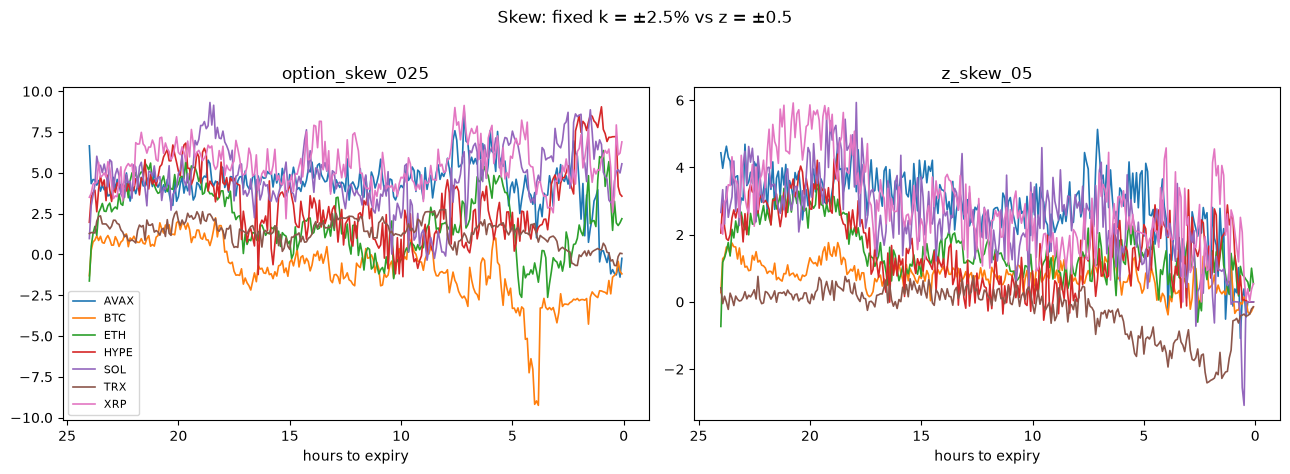

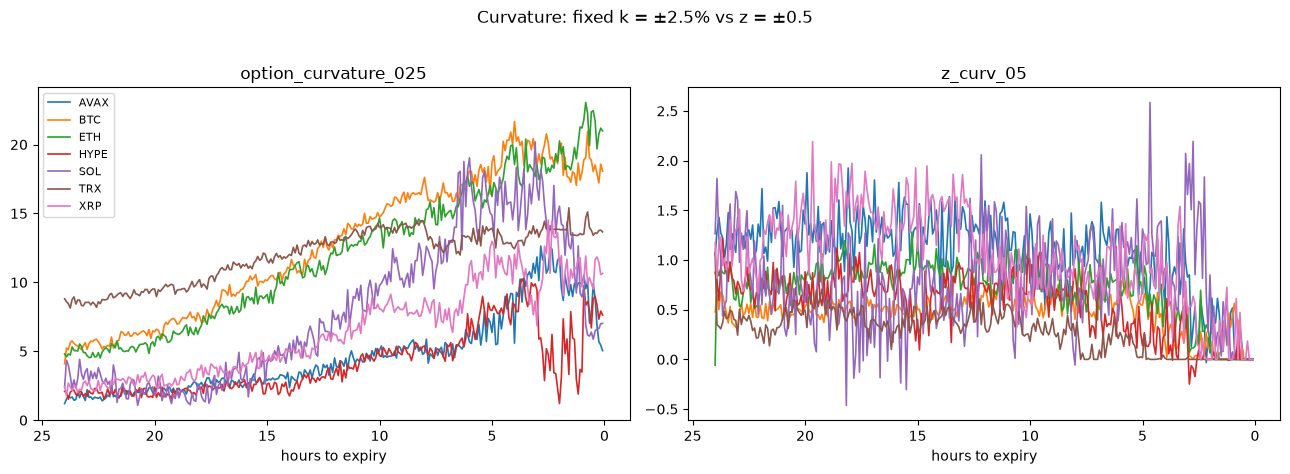

In [32]:
zf["skew_025_rel"] = zf["option_skew_025"] / zf["option_iv_atm_forward"]
zf["curv_025_rel"] = zf["option_curvature_025"] / zf["option_iv_atm_forward"]
zf["z_skew_05_rel"] = zf["z_skew_05"] / zf["option_iv_atm_forward"]
zf["z_curv_05_rel"] = zf["z_curv_05"] / zf["option_iv_atm_forward"]

PAIRS = [
    ("skew", "option_skew_025", "z_skew_05"),
    ("curvature", "option_curvature_025", "z_curv_05"),
    ("skew / ATM", "skew_025_rel", "z_skew_05_rel"),
    ("curvature / ATM", "curv_025_rel", "z_curv_05_rel"),
]

rows = []
for asset, g in zf.groupby("underlying"):
    for label, kcol, zcol in PAIRS:
        both = g.dropna(subset=[kcol, zcol])
        rows.append({
            "underlying": asset, "measure": label, "n_both": len(both),
            "eta2_fixed_k": eta_squared(both, kcol),
            "eta2_z": eta_squared(both, zcol),
        })
stationarity = pd.DataFrame(rows)
stationarity["z_minus_k"] = stationarity["eta2_z"] - stationarity["eta2_fixed_k"]
display(stationarity.round(3))

plot_median_by_tte(zf, ["option_skew_025", "z_skew_05"], "Skew: fixed k = ±2.5% vs z = ±0.5")
plot_median_by_tte(zf, ["option_curvature_025", "z_curv_05"], "Curvature: fixed k = ±2.5% vs z = ±0.5")

# Part F — Dynamics

## 13. Surface-change distributions and the settlement window (audit B4)

Deribit daily options settle to the 30-minute TWAP of the index from 07:30 to 08:00 UTC. During the last six states (`minutes_to_expiry ≤ 30`) part of the settlement price is already fixed, so quotes and implied volatilities stop behaving like those of a European option. The comparison below shows whether level and change distributions break inside that window.

,group,feature,n,missing_pct,mean,std,skew,excess_kurtosis,min,q001,q01,q05,median,q95,q99,q999,max
0,AVAX,atm_iv_change_5m,4040,12.326389,-0.009816,1.808612,0.729228,15.569772,-15.022090,-10.274397,-5.534783,-2.404532,-0.022827,2.486150,5.567680,12.738610,19.273770
1,AVAX,atm_iv_change_15m,3937,14.561632,-0.048183,2.579547,1.530606,21.481461,-16.321622,-15.565523,-6.799562,-3.489023,-0.134542,3.671368,8.311515,19.033894,37.388575
2,AVAX,atm_iv_change_1h,3663,20.507812,-0.458071,4.108576,0.576259,6.566625,-23.193689,-21.684455,-10.618068,-6.168981,-0.542824,6.433287,11.712209,21.103222,36.603605
3,AVAX,skew_025_change_5m,3775,18.077257,0.028220,2.462769,0.243550,11.469928,-18.116592,-14.765594,-7.224060,-3.275025,0.000000,3.639642,7.304426,14.979234,21.720640
4,AVAX,skew_025_change_15m,3584,22.222222,0.048721,3.105528,0.942119,16.343172,-22.304751,-16.816091,-8.863215,-4.274821,0.025480,4.523854,9.263996,21.544210,37.396504
5,AVAX,skew_025_change_1h,3112,32.465278,0.119800,4.308015,-0.503440,23.023222,-43.785195,-40.441294,-10.824827,-5.610544,0.049853,5.865898,14.382772,24.641361,41.297329
6,AVAX,curvature_025_change_5m,3775,18.077257,0.028520,1.512722,-0.591609,13.838146,-16.656750,-9.682882,-4.212853,-2.166412,0.030207,2.162327,4.274911,7.956509,13.662130
7,AVAX,curvature_025_change_15m,3584,22.222222,0.128857,1.937709,-2.768937,64.648353,-39.907683,-11.736708,-5.025889,-2.196806,0.127110,2.652991,6.007774,11.510191,15.027277
8,AVAX,curvature_025_change_1h,3112,32.465278,0.433213,2.556151,0.450519,20.489824,-28.176886,-14.691149,-6.797231,-2.369202,0.325405,3.728188,10.165239,17.590411,21.547630
9,AVAX,skew_050_change_5m,3835,16.775174,0.048190,3.066246,0.131869,6.815680,-21.664139,-16.538224,-8.664755,-4.674665,0.000000,4.944389,9.453369,15.440853,24.893690


median_abs                                            p99_abs                                  
segment                          1h before window rest of session settlement window 1h before window rest of session settlement window
feature               underlying                                                                                                      
atm_iv_change_5m      AVAX                  0.591           0.631             0.129            8.485           6.789            15.634
                      BTC                   0.701           0.329             0.618            4.101           2.540             8.421
                      ETH                   0.578           0.381             0.365            3.402           3.073             3.363
                      HYPE                  1.120           0.567             0.041           11.199           8.606             8.508
                      SOL                   0.838           1.275             0.286            9.569           8.566            24.777
                      TRX                   0.102           0.272             0.102            1.928           2.478             1.217
                      XRP                   0.746           0.677             0.355           12.668           5.705            18.994
option_iv_atm_forward AVAX                 75.532          79.687            77.323          125.676         125.452           132.957
                      BTC                  26.118          25.461            27.435           37.074          48.671            43.384
                      ETH                  32.490          32.689            34.291           41.676          59.615            42.219
                      HYPE                 64.971          62.599            64.801           86.508          76.334            87.379
                      SOL                  58.183          54.407            61.487          104.866          84.402           147.889
                      TRX                  23.970          21.587            24.379           36.241          30.482            28.791
                      XRP                  64.157          65.150            63.485          123.569         105.485           128.718
skew_025_change_5m    AVAX                  0.792           0.986             0.817           11.448           9.244            14.407
                      BTC                   0.269           0.407             0.279            3.564           3.324             3.282
                      ETH                   0.575           0.526             0.387            8.383           3.844             3.345
                      HYPE                  0.389           0.856             0.589            6.933          11.871             6.353
                      SOL                   0.522           1.121             0.527            6.083           9.741             5.189
                      TRX                   0.061           0.172             0.062            1.000           2.401             0.944
                      XRP                   1.005           0.990             1.004            9.208           7.744             6.593

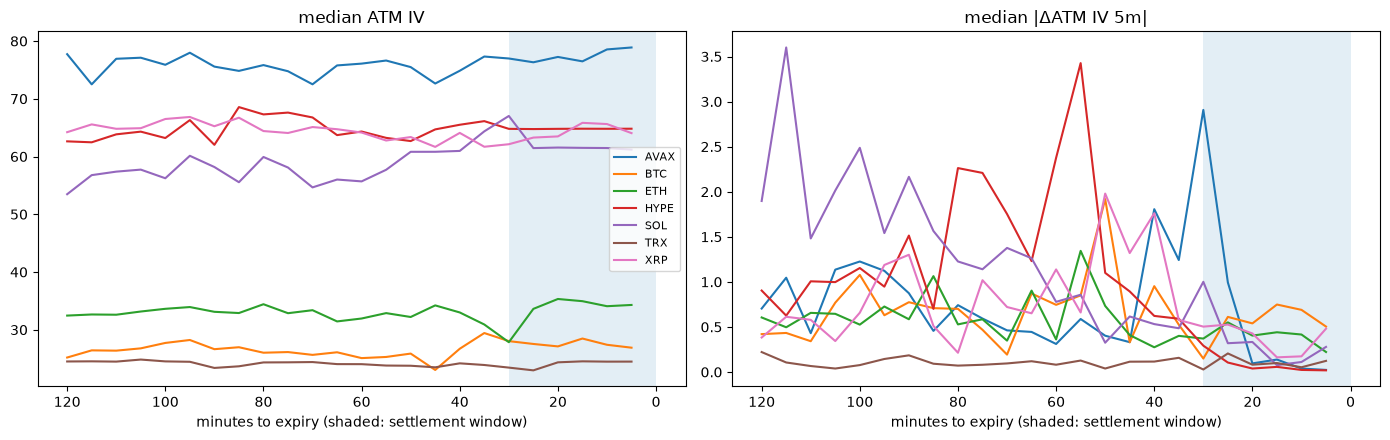

In [33]:
dyn_summary = feature_summary(features, OPTION_DYNAMIC, group_col="underlying")
display(dyn_summary)

settle_rows = []
for asset, g in features.groupby("underlying"):
    for col in ["option_iv_atm_forward", "atm_iv_change_5m", "skew_025_change_5m"]:
        if col not in g.columns:
            continue
        for label, part in [("settlement window", g[g["in_settlement_window"]]),
                            ("1h before window", g[g["minutes_to_expiry"].between(35, 90)]),
                            ("rest of session", g[g["minutes_to_expiry"] > 90])]:
            s = clean_numeric(part, col)
            settle_rows.append({
                "underlying": asset, "feature": col, "segment": label, "n": len(s),
                "median": s.median() if len(s) else np.nan,
                "median_abs": s.abs().median() if len(s) else np.nan,
                "p99_abs": s.abs().quantile(0.99) if len(s) else np.nan,
            })
settlement = pd.DataFrame(settle_rows)
display(settlement.pivot_table(index=["feature", "underlying"], columns="segment", values=["median_abs", "p99_abs"]).round(3))

last = features[features["minutes_to_expiry"] <= 120]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for asset, g in last.groupby("underlying"):
    m = g.groupby("minutes_to_expiry")["option_iv_atm_forward"].median().sort_index(ascending=False)
    axes[0].plot(m.index, m.values, label=asset)
    if "atm_iv_change_5m" in g.columns:
        a = g.groupby("minutes_to_expiry")["atm_iv_change_5m"].apply(lambda s: s.abs().median()).sort_index(ascending=False)
        axes[1].plot(a.index, a.values, label=asset)
for ax, title in zip(axes, ["median ATM IV", "median |ΔATM IV 5m|"]):
    ax.axvspan(0, 30, alpha=0.12)
    ax.invert_xaxis()
    ax.set_xlabel("minutes to expiry (shaded: settlement window)")
    ax.set_title(title)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 14. Persistence within the session

Level features that are persistent are candidate **structural** inputs; changes with near-zero autocorrelation behave like innovations. All autocorrelations are computed on the exact 5-minute grid and never cross the 08:00 boundary.

lag_minutes                         5      30     60     120
feature               underlying                            
atm_iv_change_5m      AVAX       -0.248  0.002 -0.021  0.004
                      BTC        -0.110 -0.011 -0.021 -0.010
                      ETH        -0.121 -0.019 -0.008  0.011
                      HYPE       -0.317 -0.048 -0.032  0.064
                      SOL        -0.288 -0.001 -0.006  0.033
                      TRX        -0.319  0.076 -0.019 -0.010
                      XRP        -0.198 -0.016 -0.039 -0.010
option_curvature_025  AVAX        0.911  0.801  0.703  0.504
                      BTC         0.695  0.671  0.645  0.592
                      ETH         0.864  0.845  0.829  0.796
                      HYPE        0.886  0.690  0.674  0.569
                      SOL         0.874  0.797  0.738  0.655
                      TRX         0.991  0.973  0.952  0.913
                      XRP         0.938  0.852  0.790  0.669
option_iv_atm_forward AVAX        0.993  0.983  0.972  0.957
                      BTC         0.777  0.756  0.738  0.703
                      ETH         0.883  0.867  0.848  0.814
                      HYPE        0.976  0.953  0.938  0.906
                      SOL         0.961  0.931  0.901  0.865
                      TRX         0.978  0.937  0.891  0.815
                      XRP         0.991  0.972  0.952  0.911
option_skew_025       AVAX        0.916  0.749  0.600  0.426
                      BTC         0.976  0.909  0.851  0.728
                      ETH         0.954  0.907  0.854  0.775
                      HYPE        0.872  0.602  0.620  0.507
                      SOL         0.925  0.799  0.714  0.564
                      TRX         0.992  0.953  0.890  0.729
                      XRP         0.932  0.814  0.703  0.522
rr_25d                AVAX        0.749  0.609  0.518  0.464
                      BTC         0.328  0.295  0.285  0.263
                      ETH         0.785  0.764  0.744  0.706
                      HYPE        0.889  0.837  0.794  0.692
                      SOL         0.782  0.696  0.621  0.523
                      TRX         0.747  0.511  0.392  0.299
                      XRP         0.919  0.827  0.764  0.608
skew_025_change_5m    AVAX       -0.340 -0.008 -0.029  0.033
                      BTC        -0.251  0.020  0.019  0.039
                      ETH        -0.100  0.003  0.019 -0.002
                      HYPE       -0.357 -0.137  0.172 -0.055
                      SOL        -0.253 -0.034  0.032 -0.031
                      TRX        -0.104  0.060  0.003 -0.011
                      XRP        -0.315 -0.051 -0.032  0.006
z_curv_05             AVAX        0.482  0.353  0.251  0.222
                      BTC         0.648  0.378  0.288  0.203
                      ETH         0.090  0.072  0.049  0.042
                      HYPE        0.595  0.422  0.379  0.287
                      SOL         0.427  0.256  0.157  0.061
                      TRX         0.756  0.539  0.366  0.225
                      XRP         0.733  0.447  0.334  0.287
z_skew_05             AVAX        0.661  0.544  0.476  0.421
                      BTC         0.943  0.873  0.829  0.754
                      ETH         0.965  0.920  0.888  0.847
                      HYPE        0.814  0.728  0.647  0.542
                      SOL         0.610  0.499  0.398  0.337
                      TRX         0.897  0.764  0.635  0.431
                      XRP         0.837  0.688  0.610  0.489

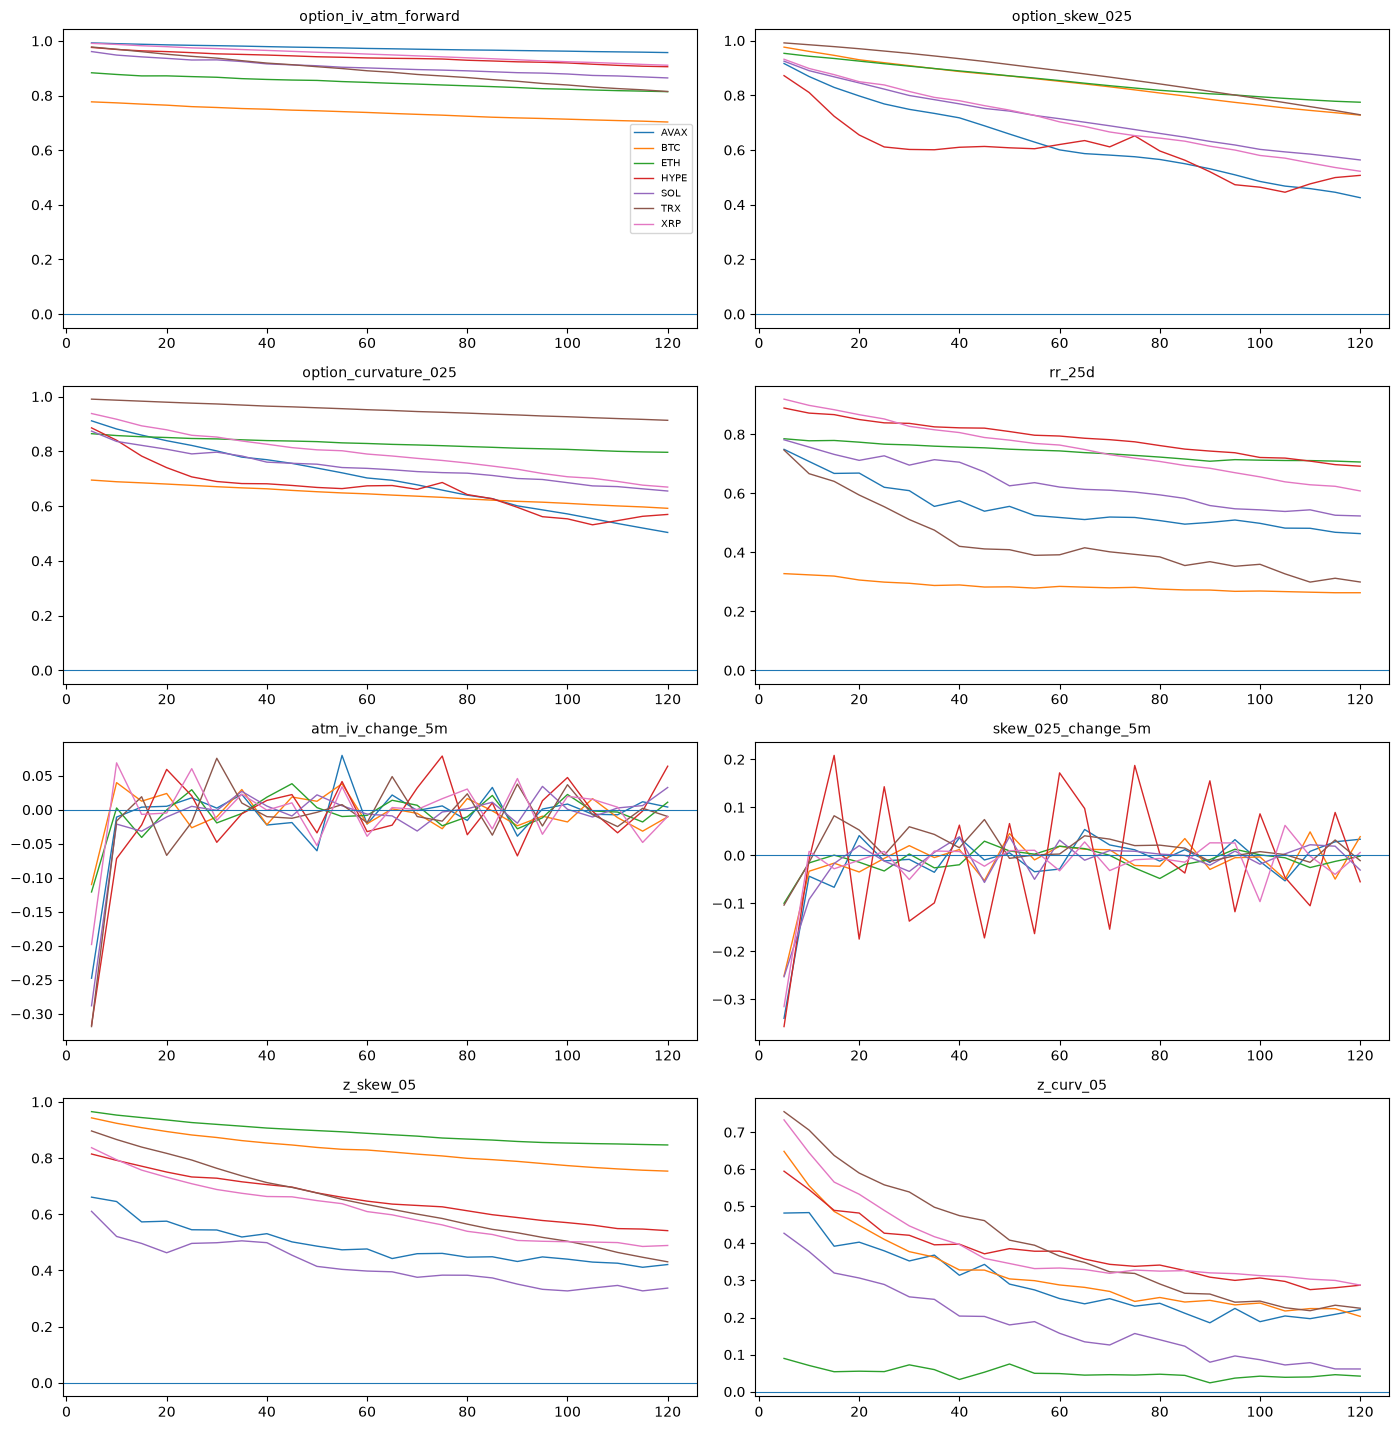

In [34]:
acf_frames = []
for col in [c for c in ["option_iv_atm_forward", "option_skew_025", "option_curvature_025", "rr_25d",
                        "atm_iv_change_5m", "skew_025_change_5m"] if c in features.columns]:
    acf_frames.append(within_session_acf(features, col, max_lag=24))
for col in ["z_skew_05", "z_curv_05"]:
    acf_frames.append(within_session_acf(zf, col, max_lag=24))
option_acf = pd.concat(acf_frames, ignore_index=True)

summary_lags = [5, 30, 60, 120]
display(
    option_acf[option_acf["lag_minutes"].isin(summary_lags)]
    .pivot_table(index=["feature", "underlying"], columns="lag_minutes", values="acf")
    .round(3)
)

feats = option_acf["feature"].unique()
fig, axes = plt.subplots(math.ceil(len(feats) / 2), 2, figsize=(14, 3.6 * math.ceil(len(feats) / 2)))
for ax, feat in zip(np.atleast_1d(axes).ravel(), feats):
    for asset, g in option_acf[option_acf["feature"] == feat].groupby("underlying"):
        ax.plot(g["lag_minutes"], g["acf"], linewidth=1, label=asset)
    ax.axhline(0, linewidth=0.8)
    ax.set_title(feat, fontsize=10)
np.atleast_1d(axes).ravel()[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

# Part G — Robustness

## 15. Linear USDC vs inverse families (BTC, ETH)

BTC and ETH list both linear USDC and inverse options for the same expiry. The primary family is linear USDC. If both families give the same ATM IV and the same changes, the primary-family choice is harmless; a persistent gap or weak change correlation would mean one family's surface is dominated by stale or mark-sourced quotes.

In [35]:
fam_cols = relation_columns("option_surface_feature_state")
if {"iv_atm_forward", "option_family_id", "state_id"}.issubset(fam_cols):
    fam = q(
        """
        SELECT state_id, state_time, underlying, option_family_id, instrument_type,
               iv_atm_forward, atm_iv_change_5m
        FROM option_surface_feature_state
        WHERE underlying IN ('BTC', 'ETH')
        """,
        "BTC/ETH families",
    )
    fam["family"] = np.where(fam["instrument_type"].str.lower().eq("linear"), "linear", "inverse")
    wide = fam.pivot_table(index=["underlying", "state_id"], columns="family",
                           values=["iv_atm_forward", "atm_iv_change_5m"], aggfunc="first")
    if {("iv_atm_forward", "linear"), ("iv_atm_forward", "inverse")}.issubset(wide.columns):
        wide["atm_gap"] = wide[("iv_atm_forward", "linear")] - wide[("iv_atm_forward", "inverse")]
        out = []
        for asset, g in wide.groupby(level="underlying"):
            ch = g[[("atm_iv_change_5m", "linear"), ("atm_iv_change_5m", "inverse")]].dropna()
            out.append({
                "underlying": asset,
                "states_both": int(g["atm_gap"].notna().sum()),
                "median_gap": g["atm_gap"].median(),
                "mad_gap": 1.4826 * (g["atm_gap"] - g["atm_gap"].median()).abs().median(),
                "p99_abs_gap": g["atm_gap"].abs().quantile(0.99),
                "corr_5m_changes": ch.corr().iloc[0, 1] if len(ch) > 20 else np.nan,
            })
        family_comparison = pd.DataFrame(out)
        display(family_comparison.round(4))
    else:
        family_comparison = pd.DataFrame()
        print("Only one family present for BTC/ETH; comparison skipped.")
else:
    family_comparison = pd.DataFrame()
    print("option_surface_feature_state lacks the needed columns; comparison skipped.")

[BTC/ETH families] 17,000 rows in 0.0s


,underlying,states_both,median_gap,mad_gap,p99_abs_gap,corr_5m_changes
0,BTC,4239,-0.3136,0.5665,3.0685,0.5582
1,ETH,4239,0.1795,0.6478,2.9399,0.6384


## 16. Level drift across sessions

Median ATM IV and skew per session. Large session-to-session level shifts are expected in crypto (volatility regimes); they matter here because any later normalization must be fitted on training history only.

option_iv_atm_forward                                                 option_skew_025                                               rr_25d                                             
underlying                   AVAX     BTC     ETH    HYPE     SOL     TRX     XRP            AVAX    BTC     ETH    HYPE     SOL    TRX     XRP   AVAX    BTC     ETH   HYPE     SOL    TRX     XRP
expiry_date                                                                                                                                                                                        
2026-09-20                 66.399  21.587  28.828  51.678  41.526  15.251  48.039           8.301  4.764  10.892  14.810   7.274 -0.222  11.770  8.529  6.616   7.366  8.005   0.169  0.508   7.323
2026-09-21                119.602  28.834  40.113  67.917  60.999  22.653  66.998           7.565  0.954  10.582  12.059   1.102 -3.212   6.580  9.504  3.589   7.409  8.525   1.701  1.367   5.265
2026-09-22                 94.302  36.072  52.023  65.304  79.739  22.880  82.986           5.367  2.381  16.421   7.006  10.198  2.338   8.852  6.959  5.729  12.319  5.952  10.535    NaN  10.896
2026-09-23                 90.954  30.943  43.169  70.274  63.133  22.586  89.174           4.883  5.443  12.734   9.818  10.031  6.109  11.218  6.619  5.661   8.785  9.505   9.745  2.899  13.081
2026-09-24                 93.628  26.549  34.918  65.588  61.455  25.556  70.486           2.786 -5.377   6.271  -2.941   2.793  4.093   0.102  3.912 -0.801   3.843 -0.546   4.330  2.669   1.041
2026-09-25                 90.237  34.145  38.025  67.767  61.121  23.107  69.901           2.267 -9.005  -4.484   0.380   3.044  1.476   0.931  3.379 -3.470  -2.965 -0.001   6.260  0.083   1.870
2026-09-26                 67.230  18.636  24.887  50.481  47.640  23.076  66.526           5.634  4.719   2.360   2.181   5.537  1.579   2.678  5.830  2.856   3.133  2.046   4.528 -0.228   3.448
2026-09-27                 55.207  13.812  22.803  43.399  41.148  18.668  55.577           4.372 -0.472   0.979   7.463   1.885 -4.487   5.207  4.277  1.471   1.481  3.755   2.836    NaN   1.489
2026-09-28                 67.786  24.414  32.389  54.755  53.435  22.074  66.406           4.771 -0.235   4.286   0.740  12.260 -0.058  11.681  5.120  3.283   3.611  1.200   8.185    NaN  11.198
2026-09-29                 77.357  24.542  33.762  62.928  57.074  21.274  65.914           3.952 -5.734  -2.403   0.312  -2.393 -1.673   5.258  4.058 -1.182  -1.084 -0.593  -3.515    NaN   2.849
2026-09-30                 87.359  24.484  33.764  66.521  56.979  19.615  69.452           2.609 -1.017   1.340  -1.074   3.870  0.848   6.536  3.024  0.739   2.604 -0.926   4.243  0.577   6.700
2026-10-01                 80.046  26.021  30.947  67.759  53.511  20.006  59.387           4.656  0.246   2.531   4.984  -0.066 -0.060   3.828  4.088  0.653   0.828  4.417  -0.171  0.872   2.668
2026-10-02                 70.864  26.669  30.854  65.599  52.394  20.069  62.370           4.558  0.090   5.236   0.849   0.938  1.836   5.667  3.835  0.845   2.660  1.131   0.548  0.014   3.542
2026-10-03                 60.187  18.689  21.981  48.152  42.073  19.067  51.880           8.459  2.989  -7.711   5.758   6.616  7.150   7.038  6.276  1.380   6.992  3.106   3.772  0.129   6.224
2026-10-04                 42.068  14.126  19.131  39.990  36.207  15.066  37.154           2.593 -1.049  -4.704   0.583   4.817  3.411   4.815  2.336  0.018  -2.454 -0.284   2.894  0.227   4.337
2026-10-05                 61.203  21.881  25.679  51.719  44.249  20.437  45.547           4.073 -2.180  -2.406  -1.637   6.027  1.307   9.467  3.613  0.167  -1.815  0.725   4.256  0.848   5.750

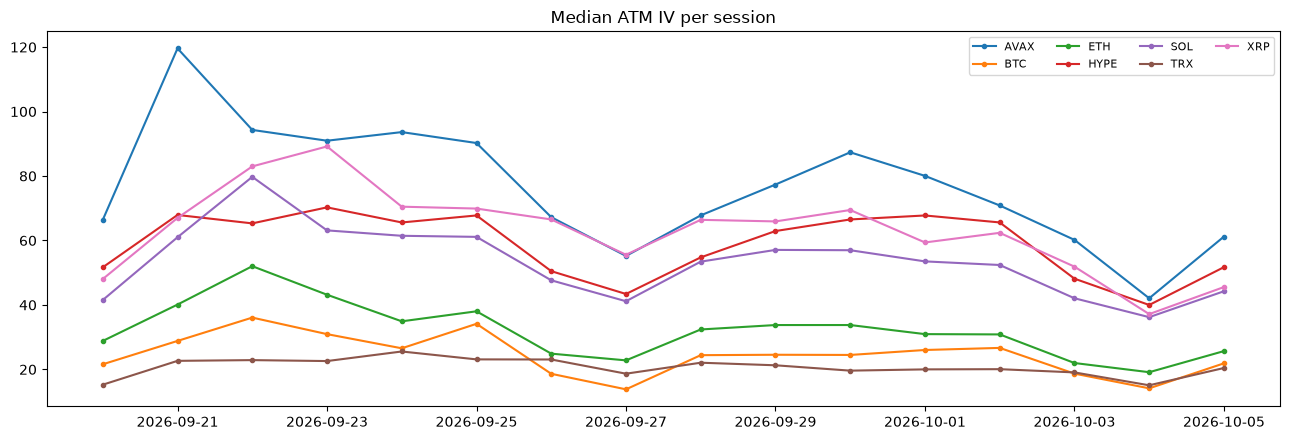

In [36]:
session_levels = (
    features.groupby(["expiry_date", "underlying"])[
        [c for c in ["option_iv_atm_forward", "option_skew_025", "rr_25d"] if c in features.columns]
    ]
    .median()
    .unstack("underlying")
)
display(session_levels.round(3))

fig, ax = plt.subplots(figsize=(13, 4.5))
for asset in ASSETS:
    s = features[features["underlying"] == asset].groupby("expiry_date")["option_iv_atm_forward"].median()
    ax.plot(s.index, s.values, marker="o", ms=3, label=asset)
ax.set_title("Median ATM IV per session")
ax.legend(fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

# Part H — Addendum: Surface Measurement Quality

The first run of this notebook (16 sessions, surfaces v0.1) found:

- 92–100% of core nodes are mark-sourced in the last hour;
- 5m changes across a quote ↔ mark switch have 3–4× the tail of same-source changes;
- alt 5m ATM changes have lag-1 autocorrelation of about −0.3, the signature of measurement noise;
- BTC/ETH linear and inverse families agree in level but their 5m ATM changes correlate at only 0.04 / 0.13, with BTC ATM IV spikes up to 457%.

From surfaces v0.2 / option features v0.2.0 the pipeline records the IV source of every node, computes changes only when all nodes keep their source class, and no longer requires the futures stream. This part checks those changes on the real data and prototypes a fitted smile as the candidate answer to audit A2.

> Requires a rebuild with `build_features.py --refresh-upstream` (canonical, normalization and surface view definitions changed).

## 17. IV-source composition and blocked changes (pipeline v0.2)

`node_mark_share` is the share of interpolated nodes with at least one mark-sourced side; `base_mark_iv_row_share` the share of surface-eligible contracts priced by the mark model; `core_source_switch_5m` marks contiguous states whose core change was withheld because a node changed source.

In [37]:
NEW_COLS = ["node_mark_share", "base_mark_iv_row_share", "core_nodes_with_mark",
            "core_source_switch_5m", "atm_source_switch_5m", "src_k_000", "core_iv_source_signature",
            "in_settlement_window", "option_snapshot_ready"]
missing_new = [c for c in NEW_COLS if c not in features.columns]
PIPELINE_V02 = not missing_new
if not PIPELINE_V02:
    print(f"Feature table predates surfaces v0.2 (missing {missing_new}).")
    print("Rebuild with build_features.py --refresh-upstream; Sections 17-19 are partly skipped.")
else:
    src_tab = (
        features[features["core_smile_usable"].fillna(False).astype(bool)]
        .groupby(["underlying", "tte_bucket"], observed=True)
        .agg(
            node_mark_pct=("node_mark_share", lambda s: 100 * s.mean()),
            core_any_mark_pct=("core_nodes_with_mark", lambda s: 100 * (s > 0).mean()),
            row_mark_pct=("base_mark_iv_row_share", lambda s: 100 * s.mean()),
        )
        .round(1)
    )
    display(src_tab.unstack("tte_bucket"))

    blocked = features.groupby("underlying").agg(
        core_changes_5m=("core_surface_change_5m_ready", lambda s: int(s.fillna(False).astype(bool).sum())),
        core_blocked_by_switch=("core_source_switch_5m", lambda s: int(s.fillna(False).astype(bool).sum())),
        atm_blocked_by_switch=("atm_source_switch_5m", lambda s: int(s.fillna(False).astype(bool).sum())),
    )
    blocked["blocked_pct"] = 100 * blocked["core_blocked_by_switch"] / (
        blocked["core_changes_5m"] + blocked["core_blocked_by_switch"]
    )
    display(blocked.round(2))

    print("Core-node source signatures (top 8 per asset, % of usable states):")
    sig = (
        features[features["core_smile_usable"].fillna(False).astype(bool)]
        .groupby("underlying")["core_iv_source_signature"]
        .value_counts(normalize=True)
        .mul(100).round(1)
        .groupby(level=0).head(8)
    )
    display(sig.to_frame("pct"))

    # Option-side recovery from decoupling the futures gate (audit B1).
    recov = features.assign(
        opt=features["option_snapshot_ready"].fillna(False).astype(bool),
        res=features["state_research_ready"].fillna(False).astype(bool),
        core=features["core_smile_usable"].fillna(False).astype(bool),
    )
    display(
        recov.groupby("underlying").agg(
            core_usable=("core", "sum"),
            core_usable_without_futures=("core", lambda s: int((s & ~recov.loc[s.index, "res"]).sum())),
        )
    )

node_mark_pct                                        core_any_mark_pct                                            row_mark_pct                                       
tte_bucket ≤30m (settle) 30m–1h  1–3h  3–6h 6–12h 12–18h 18–24h     ≤30m (settle) 30m–1h   1–3h   3–6h  6–12h 12–18h 18–24h ≤30m (settle) 30m–1h  1–3h  3–6h 6–12h 12–18h 18–24h
underlying                                                                                                                                                                      
AVAX                99.2   95.7  84.1  67.9  42.0   21.4   16.3             100.0  100.0   88.6   65.0   17.2    4.9    4.9          99.6   97.3  90.8  81.4  64.8   46.4   37.5
BTC                100.0   98.1  90.6  84.4  77.0   62.2   47.8             100.0  100.0   98.6  100.0   88.4   51.7   17.3          99.5   97.2  93.0  85.9  78.8   66.9   54.4
ETH                100.0   98.3  89.6  83.2  70.8   50.3   33.2             100.0  100.0  100.0   99.8   74.2   28.0    3.8          99.8   98.1  93.2  86.3  76.7   63.4   45.7
HYPE               100.0   98.1  89.5  77.9  58.9   48.3   35.3             100.0  100.0   98.1   82.2   37.4   13.6   10.1          99.8   97.6  91.5  85.4  73.6   66.4   53.6
SOL                100.0   99.3  94.0  85.6  73.2   64.2   52.9             100.0  100.0  100.0  100.0   74.9   48.8   28.9          99.8   98.7  95.2  89.1  80.5   74.5   65.6
TRX                100.0  100.0  98.8  94.1  87.3   79.9   70.8             100.0  100.0  100.0  100.0  100.0   99.4   77.6         100.0  100.0  97.7  91.1  83.8   72.7   64.2
XRP                 99.8   98.4  92.7  78.7  66.0   44.5   40.4             100.0  100.0   95.9   79.8   64.2   23.3   22.3          99.7   97.8  93.4  84.3  74.0   59.4   54.0

,core_changes_5m,core_blocked_by_switch,atm_blocked_by_switch,blocked_pct
underlying,,,,
AVAX,3775,441,176,10.46
BTC,3671,545,118,12.93
ETH,3645,571,116,13.54
HYPE,3504,712,165,16.89
SOL,3324,892,222,21.16
TRX,3853,363,127,8.61
XRP,3465,627,196,15.32


Core-node source signatures (top 8 per asset, % of usable states):


pct
underlying core_iv_source_signature      
AVAX       QQ|QQ|QQ                  73.2
           MM|QQ|MM                   8.4
           MM|MM|MM                   5.8
           MQ|QQ|QQ                   3.8
           MQ|QQ|QM                   2.1
           MM|QQ|QM                   1.9
           MM|MQ|MM                   1.4
           MM|QM|MM                   1.0
BTC        QQ|QQ|QQ                  34.9
           MM|QQ|MM                  25.1
           MQ|QQ|MM                   6.4
           QQ|QQ|QM                   6.2
           QQ|QQ|MM                   4.3
           MQ|QQ|QM                   4.2
           MM|QQ|QM                   3.6
           MM|MM|MM                   3.3
ETH        QQ|QQ|QQ                  47.6
           MM|QQ|MM                  15.1
           MQ|QQ|QQ                   5.7
           MQ|QQ|QM                   5.1
           MM|MM|MM                   4.2
           MM|QQ|QM                   4.1
           QQ|QQ|MM                   4.0
           QQ|QQ|QM                   3.5
HYPE       QQ|QQ|QQ                  61.6
           MQ|QQ|QM                   7.7
           MM|QQ|MM                   7.3
           MQ|QQ|QQ                   5.1
           MM|MM|MM                   4.6
           MM|MQ|MM                   2.9
           MM|QQ|QM                   2.8
           QQ|QQ|QM                   2.7
SOL        QQ|QQ|QQ                  36.2
           MM|QQ|MM                  17.6
           MQ|QQ|QQ                   9.2
           MM|QQ|QM                   7.5
           MQ|QQ|QM                   6.8
           MM|MM|MM                   5.3
           MM|QM|MM                   4.0
           MM|QQ|QQ                   3.9
TRX        MM|QQ|MM                  27.2
           MQ|QQ|QM                  15.0
           MM|MM|MM                  14.5
           MQ|QQ|QQ                  11.8
           MQ|QQ|MM                   8.2
           MM|QM|MM                   6.1
           QQ|QQ|QQ                   5.4
           MM|MQ|MM                   4.8
XRP        QQ|QQ|QQ                  50.6
           MM|MM|MM                   9.7
           MM|QQ|MM                   9.2
           MQ|QQ|QQ                   8.3
           MQ|QQ|QM                   7.1
           MM|QQ|QM                   5.7
           MM|MQ|MM                   2.3
           MQ|QQ|MM                   2.2

,core_usable,core_usable_without_futures
underlying,,
AVAX,4239,305
BTC,4239,305
ETH,4239,305
HYPE,4239,305
SOL,4239,305
TRX,4239,305
XRP,4120,305


## 18. Is a 5-minute surface change signal or noise?

If an observed level is $y_t = s_t + n_t$, with $s_t$ a random walk and $n_t$ white measurement noise, the 5-minute change has lag-1 autocorrelation

$$
\rho_1 = -\frac{\sigma_n^2}{\sigma_{\Delta s}^2 + 2\sigma_n^2}
\quad\Longrightarrow\quad
\frac{\sigma_n^2}{\sigma_{\Delta s}^2} = \frac{-\rho_1}{1 + 2\rho_1}, \qquad -\tfrac12 < \rho_1 < 0 .
$$

The table reports $\rho_1$ and the implied noise-to-signal variance ratio for ATM, skew and curvature changes. With the v0.2 pipeline these changes are source-consistent, so any remaining noise comes from quotes and interpolation rather than source switches. Positive $\rho_1$ is reported as "no noise signature".

In [38]:
def lag1_noise(df, column):
    """Lag-1 within-session autocorrelation of a change series and the implied noise ratio."""
    a = within_session_acf(df, column, max_lag=1)
    a["rho1"] = a["acf"]
    a["noise_to_signal_var"] = np.where(
        (a["rho1"] > -0.5) & (a["rho1"] < 0), -a["rho1"] / (1 + 2 * a["rho1"]), np.nan
    )
    return a[["underlying", "feature", "rho1", "noise_to_signal_var", "n_pairs"]]

noise_tab = pd.concat(
    [lag1_noise(features, c) for c in ["atm_iv_change_5m", "skew_025_change_5m", "curvature_025_change_5m", "rr_25d_change_5m"]
     if c in features.columns],
    ignore_index=True,
)
display(noise_tab.pivot(index="underlying", columns="feature", values=["rho1", "noise_to_signal_var"]).round(3))

rho1                                                             noise_to_signal_var                                                            
feature    atm_iv_change_5m curvature_025_change_5m rr_25d_change_5m skew_025_change_5m    atm_iv_change_5m curvature_025_change_5m rr_25d_change_5m skew_025_change_5m
underlying                                                                                                                                                             
AVAX                 -0.248                  -0.363           -0.386             -0.340               0.491                   1.324            1.697              1.058
BTC                  -0.110                  -0.290           -0.285             -0.251               0.141                   0.690            0.662              0.505
ETH                  -0.121                  -0.260           -0.225             -0.100               0.159                   0.542            0.409              0.125
HYPE                 -0.317                  -0.372           -0.426             -0.357               0.864                   1.447            2.892              1.246
SOL                  -0.288                  -0.291           -0.335             -0.253               0.680                   0.695            1.013              0.512
TRX                  -0.319                  -0.295           -0.384             -0.104               0.879                   0.719            1.660              0.131
XRP                  -0.198                  -0.294           -0.344             -0.315               0.328                   0.716            1.106              0.853

## 19. ATM spikes and family agreement, measured robustly

The first run showed BTC ATM IV reaching 457% and a near-zero correlation between linear and inverse 5m ATM changes. Pearson correlation is dominated by a handful of extreme values, so agreement is re-measured with:

- **Spearman** rank correlation (insensitive to spikes);
- **Pearson after trimming** the 0.5% largest absolute changes in either family;
- separately for 5m, 15m and 1h changes (if the 5m disagreement is noise, longer horizons should agree better);
- by time-to-expiry bucket.

The spike table lists the most extreme ATM observations with their context.

In [39]:
spike_cols = [c for c in [
    "state_time", "underlying", "minutes_to_expiry", "option_iv_atm_forward", "atm_iv_change_5m",
    "src_k_000", "core_iv_source_signature", "core_max_interpolation_span",
    "option_base_eligible_rows", "option_two_sided_eligible_rows",
    "option_median_two_sided_spread_bps", "realized_vol_1h_annualized",
] if c in features.columns]
for asset in ["BTC", "ETH"]:
    g = features[features["underlying"] == asset]
    print(f"\n{asset}: highest ATM IV states")
    display(g.nlargest(10, "option_iv_atm_forward")[spike_cols])
    print(f"{asset}: largest |ΔATM IV 5m|")
    display(g.loc[g["atm_iv_change_5m"].abs().nlargest(10).index, spike_cols])

fam2 = q(
    """
    SELECT state_id, state_time, underlying, session_id, minutes_to_expiry, instrument_type,
           iv_atm_forward, atm_iv_change_5m, atm_iv_change_15m, atm_iv_change_1h
    FROM option_surface_feature_state
    WHERE underlying IN ('BTC', 'ETH')
    """,
    "BTC/ETH family changes",
)
fam2["family"] = np.where(fam2["instrument_type"].str.lower().eq("linear"), "linear", "inverse")
fam2["tte_bucket"] = pd.cut(fam2["minutes_to_expiry"], bins=TTE_EDGES, labels=TTE_LABELS, right=True)

agree_rows = []
for horizon in ["atm_iv_change_5m", "atm_iv_change_15m", "atm_iv_change_1h"]:
    w = fam2.pivot_table(index=["underlying", "state_id", "tte_bucket"], columns="family",
                         values=horizon, aggfunc="first", observed=True).dropna()
    if not {"linear", "inverse"}.issubset(w.columns):
        continue
    for (asset, bucket), g in w.groupby(level=["underlying", "tte_bucket"], observed=True):
        if len(g) < 30:
            continue
        lim_l, lim_i = g["linear"].abs().quantile(0.995), g["inverse"].abs().quantile(0.995)
        trimmed = g[(g["linear"].abs() <= lim_l) & (g["inverse"].abs() <= lim_i)]
        agree_rows.append({
            "underlying": asset, "horizon": horizon.replace("atm_iv_change_", ""), "tte_bucket": bucket,
            "n": len(g),
            "pearson": g["linear"].corr(g["inverse"]),
            "pearson_trimmed": trimmed["linear"].corr(trimmed["inverse"]),
            "spearman": g["linear"].corr(g["inverse"], method="spearman"),
        })
family_agreement = pd.DataFrame(agree_rows)
if not family_agreement.empty:
    display(
        family_agreement.pivot_table(index=["underlying", "tte_bucket"], columns="horizon",
                                     values="spearman", observed=True).round(3)
    )
    display(
        family_agreement.groupby(["underlying", "horizon"])[["pearson", "pearson_trimmed", "spearman"]]
        .median().round(3)
    )


BTC: highest ATM IV states


,state_time,underlying,minutes_to_expiry,option_iv_atm_forward,atm_iv_change_5m,src_k_000,core_iv_source_signature,core_max_interpolation_span,option_base_eligible_rows,option_two_sided_eligible_rows,option_median_two_sided_spread_bps,realized_vol_1h_annualized
26209,2026-10-02 08:00:00+00:00,BTC,1440,457.556512,NaN,QM,MM|QM|MM,0.011300,29.0,4.0,19919.526217,0.277404
4180,2026-09-21 09:45:00+00:00,BTC,1335,58.046409,0.533399,QQ,QQ|QQ|QQ,0.011696,31.0,20.0,3686.763687,NaN
4173,2026-09-21 09:40:00+00:00,BTC,1340,57.513010,1.582608,QQ,QQ|QQ|QQ,0.011834,31.0,20.0,4000.000000,NaN
4166,2026-09-21 09:35:00+00:00,BTC,1345,55.930402,2.614108,QQ,QQ|QQ|QQ,0.011834,31.0,20.0,4410.774411,NaN
4187,2026-09-21 09:50:00+00:00,BTC,1330,55.457260,-2.589148,QQ,QQ|QQ|QQ,0.011834,31.0,20.0,3739.130435,NaN
4159,2026-09-21 09:30:00+00:00,BTC,1350,53.316294,3.059200,QQ,QQ|QQ|QQ,0.011834,31.0,20.0,4000.000000,NaN
4103,2026-09-21 08:50:00+00:00,BTC,1390,53.001526,2.492125,QQ,QQ|QQ|QQ,0.011696,31.0,18.0,2917.933131,NaN
4194,2026-09-21 09:55:00+00:00,BTC,1325,52.996810,-2.460451,QQ,QQ|QQ|QQ,0.011834,31.0,18.0,3094.098884,NaN
4110,2026-09-21 08:55:00+00:00,BTC,1385,52.657673,-0.343853,QQ,QQ|QQ|QQ,0.011696,31.0,18.0,3011.664899,NaN
4131,2026-09-21 09:10:00+00:00,BTC,1370,52.088581,0.822832,QQ,QQ|QQ|QQ,0.011561,31.0,17.0,2465.753425,NaN


BTC: largest |ΔATM IV 5m|


,state_time,underlying,minutes_to_expiry,option_iv_atm_forward,atm_iv_change_5m,src_k_000,core_iv_source_signature,core_max_interpolation_span,option_base_eligible_rows,option_two_sided_eligible_rows,option_median_two_sided_spread_bps,realized_vol_1h_annualized
6042,2026-09-22 07:55:00+00:00,BTC,5,49.985890,10.820581,QM,MM|QM|MM,0.006006,36.0,1.0,6666.666667,NaN
4089,2026-09-21 08:40:00+00:00,BTC,1400,49.236518,9.391767,QQ,QQ|QQ|QQ,0.011696,31.0,15.0,3076.923077,NaN
18117,2026-09-28 07:40:00+00:00,BTC,20,27.118765,7.703779,MQ,MM|MQ|MM,0.006192,29.0,1.0,6666.666667,0.310409
18110,2026-09-28 07:35:00+00:00,BTC,25,19.414986,-7.286645,MQ,MM|MQ|MM,0.006192,29.0,1.0,13333.333333,0.300708
22107,2026-09-30 07:10:00+00:00,BTC,50,25.873797,4.394054,QM,MM|QM|MM,0.006192,29.0,1.0,8000.000000,NaN
26167,2026-10-02 07:30:00+00:00,BTC,30,27.470852,-4.268627,MQ,MM|MQ|MM,0.011300,29.0,1.0,10000.000000,0.159529
17956,2026-09-28 05:45:00+00:00,BTC,135,29.642873,-4.195947,QQ,MM|QQ|MM,0.006154,29.0,3.0,5454.545455,0.543254
18082,2026-09-28 07:15:00+00:00,BTC,45,23.037614,-4.169223,QM,MM|QM|MM,0.006154,29.0,1.0,12941.176471,0.262520
6035,2026-09-22 07:50:00+00:00,BTC,10,39.165309,4.139707,QM,MM|QM|MM,0.006006,36.0,1.0,6666.666667,NaN
25908,2026-10-02 04:25:00+00:00,BTC,215,40.036732,3.863354,QQ,MM|QQ|QM,0.011561,29.0,8.0,5673.758865,0.738456



ETH: highest ATM IV states


,state_time,underlying,minutes_to_expiry,option_iv_atm_forward,atm_iv_change_5m,src_k_000,core_iv_source_signature,core_max_interpolation_span,option_base_eligible_rows,option_two_sided_eligible_rows,option_median_two_sided_spread_bps,realized_vol_1h_annualized
26210,2026-10-02 08:00:00+00:00,ETH,1440,371.216700,NaN,MQ,MM|MQ|QQ,0.007491,32.0,5.0,18638.858397,0.318903
4181,2026-09-21 09:45:00+00:00,ETH,1335,73.774433,0.352961,QQ,QQ|QQ|QQ,0.007491,35.0,19.0,1428.571429,NaN
4174,2026-09-21 09:40:00+00:00,ETH,1340,73.421472,1.631160,QQ,QQ|QQ|QQ,0.007491,35.0,19.0,1791.044776,NaN
4167,2026-09-21 09:35:00+00:00,ETH,1345,71.790311,8.945524,QQ,QQ|QQ|QQ,0.007491,35.0,19.0,1904.761905,NaN
4188,2026-09-21 09:50:00+00:00,ETH,1330,68.707026,-5.067407,QQ,QQ|QQ|QQ,0.007491,35.0,17.0,1538.461538,NaN
4195,2026-09-21 09:55:00+00:00,ETH,1325,66.236590,-2.470436,QQ,QQ|QQ|QQ,0.007547,35.0,18.0,1632.563977,NaN
4202,2026-09-21 10:00:00+00:00,ETH,1320,64.548577,-1.688014,QQ,QQ|QQ|QQ,0.007547,35.0,18.0,1254.370629,NaN
4209,2026-09-21 10:05:00+00:00,ETH,1315,64.176191,-0.372386,QQ,QQ|QQ|QQ,0.007547,35.0,18.0,1560.982191,NaN
4216,2026-09-21 10:10:00+00:00,ETH,1310,63.785172,-0.391019,QQ,QQ|QQ|QQ,0.007547,35.0,18.0,1314.148681,NaN
4104,2026-09-21 08:50:00+00:00,ETH,1390,63.641874,3.051649,QQ,QQ|QQ|QQ,0.007605,35.0,22.0,1973.180077,NaN


ETH: largest |ΔATM IV 5m|


,state_time,underlying,minutes_to_expiry,option_iv_atm_forward,atm_iv_change_5m,src_k_000,core_iv_source_signature,core_max_interpolation_span,option_base_eligible_rows,option_two_sided_eligible_rows,option_median_two_sided_spread_bps,realized_vol_1h_annualized
4167,2026-09-21 09:35:00+00:00,ETH,1345,71.790311,8.945524,QQ,QQ|QQ|QQ,0.007491,35.0,19.0,1904.761905,NaN
5070,2026-09-21 20:20:00+00:00,ETH,700,58.146306,7.400370,QQ,QQ|QQ|QQ,0.017392,35.0,12.0,2786.596120,0.955219
3383,2026-09-21 00:15:00+00:00,ETH,465,48.147697,6.773503,QQ,QQ|QQ|QQ,0.007663,37.0,14.0,5303.225806,NaN
3390,2026-09-21 00:20:00+00:00,ETH,460,54.832250,6.684553,QQ,QQ|QQ|QQ,0.007605,37.0,14.0,4000.000000,NaN
20015,2026-09-29 06:15:00+00:00,ETH,105,39.160078,6.555578,QQ,MM|QQ|MM,0.007605,31.0,2.0,5224.171540,0.676363
25909,2026-10-02 04:25:00+00:00,ETH,215,35.307043,6.216440,QQ,MM|QQ|QM,0.017700,30.0,7.0,6666.666667,0.512204
17943,2026-09-28 05:35:00+00:00,ETH,145,38.753157,6.047745,QQ,MM|QQ|MM,0.007782,32.0,3.0,4615.384615,0.380982
9256,2026-09-23 22:10:00+00:00,ETH,590,34.643913,5.939964,QQ,MQ|QQ|QQ,0.007605,40.0,11.0,6666.666667,0.633227
24124,2026-10-01 07:10:00+00:00,ETH,50,28.384170,-5.272272,MQ,MM|MQ|MM,0.007547,31.0,1.0,10476.190476,0.385109
4188,2026-09-21 09:50:00+00:00,ETH,1330,68.707026,-5.067407,QQ,QQ|QQ|QQ,0.007491,35.0,17.0,1538.461538,NaN


[BTC/ETH family changes] 17,000 rows in 0.0s


horizon                     15m     1h     5m
underlying tte_bucket                        
BTC        12–18h         0.768  0.930  0.548
           18–24h         0.692  0.909  0.459
           1–3h           0.663  0.887  0.483
           30m–1h           NaN    NaN  0.539
           3–6h           0.695  0.874  0.522
           6–12h          0.778  0.927  0.585
           ≤30m (settle)  0.954    NaN  0.808
ETH        12–18h         0.707  0.896  0.582
           18–24h         0.704  0.904  0.514
           1–3h           0.701  0.860  0.587
           30m–1h         0.808    NaN  0.509
           3–6h           0.673  0.906  0.492
           6–12h          0.765  0.877  0.550
           ≤30m (settle)  0.736    NaN  0.769

pearson  pearson_trimmed  spearman
underlying horizon                                    
BTC        15m        0.817            0.799     0.732
           1h         0.941            0.922     0.909
           5m         0.580            0.559     0.539
ETH        15m        0.776            0.742     0.707
           1h         0.931            0.924     0.896
           5m         0.623            0.590     0.550

## 20. Fitted smile in standardized moneyness (A2 candidate)

Node interpolation uses two strikes per node, so near expiry, when strikes are several $\sigma\sqrt\tau$ apart, it manufactures curvature and noise (Section 12). A least-squares fit uses every quoted strike at once. For each state and option family:

$$
\sigma(z) = a + b\,z + c\,z^2, \qquad z = \frac{\ln(K/F)}{\sigma_{ATM}\sqrt{\tau}},
$$

fitted by weighted least squares on **quote-sourced** OTM contracts (bid/ask-IV midpoint) with $|z| \le 2$, with weights $w_i = 1 / \max(\text{IV spread}_i,\ 0.5)^2$, so tight quotes count more. Mark-model IVs are excluded by construction.

- $a$ is the fitted ATM level, $b$ the skew per expected move, $c$ the curvature per expected move squared;
- a fit is accepted only with at least `FIT_MIN_POINTS` quotes and strikes on both sides ($z_{\min} \le -0.5$, $z_{\max} \ge 0.5$);
- the scale $\sigma_{ATM}$ comes from the pipeline's interpolated ATM IV of the same family (a prototype shortcut; a production version would iterate or use the fit itself).

This is a quadratic special case of the SVI family the framework names; it is not arbitrage-checked.

In [40]:
FIT_Z_MAX = 2.0
FIT_MIN_POINTS = 5
FIT_SPREAD_FLOOR = 0.5   # IV points
FIT_FAMILIES_EXTRA = ["BTC|reversed|BTC|BTC", "ETH|reversed|ETH|ETH"]

fit_chain = q(
    f"""
    WITH fams AS (
        SELECT DISTINCT option_family_id FROM primary_option_surface_feature_state
        UNION
        SELECT option_family_id FROM (VALUES {", ".join(f"('{f}')" for f in FIT_FAMILIES_EXTRA)}) t(option_family_id)
    ),
    atm AS (
        SELECT state_id, option_family_id, iv_atm_forward, minutes_to_expiry
        FROM option_surface_feature_state
        WHERE iv_atm_forward > 0
    )
    SELECT
        n.state_id, n.option_family_id, n.log_moneyness, n.iv_mid, n.iv_spread,
        a.iv_atm_forward, a.minutes_to_expiry
    FROM normalized_option_chain n
    JOIN fams f ON n.option_family_id = f.option_family_id
    JOIN atm a ON a.state_id = n.state_id AND a.option_family_id = n.option_family_id
    WHERE n.surface_base_eligible
      AND n.preferred_iv_source = 'bid_ask_iv_mid'
      AND n.iv_mid > 0
    """,
    "quote-sourced chain for fits",
)

fc = fit_chain
fc["scale"] = fc["iv_atm_forward"] * IV_TO_DECIMAL * np.sqrt(fc["minutes_to_expiry"] / MINUTES_PER_YEAR)
fc["z"] = fc["log_moneyness"] / fc["scale"]
fc = fc[fc["z"].abs() <= FIT_Z_MAX].copy()
fc["w"] = 1.0 / np.maximum(fc["iv_spread"].fillna(FIT_SPREAD_FLOOR * 4), FIT_SPREAD_FLOOR) ** 2
fc["y"] = fc["iv_mid"]
for p in range(5):
    fc[f"wz{p}"] = fc["w"] * fc["z"] ** p
for p in range(3):
    fc[f"wyz{p}"] = fc["w"] * fc["y"] * fc["z"] ** p

keys = ["state_id", "option_family_id"]
agg = fc.groupby(keys).agg(
    n=("z", "size"), z_min=("z", "min"), z_max=("z", "max"),
    **{f"S{p}": (f"wz{p}", "sum") for p in range(5)},
    **{f"T{p}": (f"wyz{p}", "sum") for p in range(3)},
).reset_index()

A = np.stack([
    np.stack([agg["S0"], agg["S1"], agg["S2"]], axis=-1),
    np.stack([agg["S1"], agg["S2"], agg["S3"]], axis=-1),
    np.stack([agg["S2"], agg["S3"], agg["S4"]], axis=-1),
], axis=1)
B = np.stack([agg["T0"], agg["T1"], agg["T2"]], axis=-1)
ok = (agg["n"] >= FIT_MIN_POINTS) & (agg["z_min"] <= -0.5) & (agg["z_max"] >= 0.5)
det = np.linalg.det(A)
ok &= np.abs(det) > 1e-12
coef = np.full((len(agg), 3), np.nan)
coef[ok.to_numpy()] = np.linalg.solve(A[ok.to_numpy()], B[ok.to_numpy()][..., None])[..., 0]
agg["fit_a"], agg["fit_b"], agg["fit_c"] = coef[:, 0], coef[:, 1], coef[:, 2]
agg["fit_ok"] = ok

res = fc.merge(agg[keys + ["fit_a", "fit_b", "fit_c"]], on=keys)
res["r2"] = res["w"] * (res["y"] - (res["fit_a"] + res["fit_b"] * res["z"] + res["fit_c"] * res["z"] ** 2)) ** 2
sums = res.groupby(keys)[["r2", "w"]].sum()
rmse = np.sqrt(sums["r2"] / sums["w"])
agg = agg.merge(rmse.rename("fit_wrmse").reset_index(), on=keys, how="left")
fits = agg[keys + ["n", "z_min", "z_max", "fit_ok", "fit_a", "fit_b", "fit_c", "fit_wrmse"]]
print(f"Family-states with a quote chain: {len(fits):,} | accepted fits: {int(fits['fit_ok'].sum()):,}")

[quote-sourced chain for fits] 344,754 rows in 5.3s
Family-states with a quote chain: 35,925 | accepted fits: 24,012


## 21. Fitted smile vs node features

Four tests, each against the current fixed-$k$ (and, where relevant, delta) features:

1. **Coverage** by time to expiry — the fit needs quotes on both sides, which may fail near expiry where only mark IVs remain.
2. **Clock dependence** ($\eta^2$) of skew $b/a$ and curvature $c/a$.
3. **Noise** — lag-1 autocorrelation of 5m changes in $a$, $b$, $c$ (Section 18 formula).
4. **Family agreement** — Spearman correlation of 5m and 15m changes in $a$ and $b$ between BTC/ETH linear and inverse families.

A fitted smile is the better representation if it keeps reasonable coverage while lowering clock dependence and noise and raising family agreement.

fit_pct  fixed_k_core_pct  delta25_pct  median_quotes  median_wrmse
underlying tte_bucket                                                                        
AVAX       ≤30m (settle)     0.00             93.75         2.08            2.0          0.00
           30m–1h            0.00             93.75        15.62            2.0          0.00
           1–3h             21.61             93.49        48.44            3.0          0.00
           3–6h             51.56             93.75        85.42            5.0          0.37
           6–12h            86.20             93.66        90.80            9.0          0.87
           12–18h           92.97             94.01        94.01           13.0          0.87
           18–24h           83.59             86.63        86.63           16.0          0.84
BTC        ≤30m (settle)     0.00             93.75         0.00            1.0          0.00
           30m–1h            0.00             93.75         0.00            1.0          0.00
           1–3h              0.26             93.49         5.99            2.0          0.00
           3–6h             18.40             93.75        25.52            4.0          0.00
           6–12h            55.12             93.66        59.11            5.0          0.20
           12–18h           81.34             94.01        79.69            7.0          0.31
           18–24h           75.87             86.63        79.34           10.0          0.41
ETH        ≤30m (settle)     0.00             93.75         0.00            1.0          0.00
           30m–1h            0.00             93.75         2.08            1.0          0.00
           1–3h              6.51             93.49        11.46            2.0          0.00
           3–6h             25.87             93.75        35.24            4.0          0.00
           6–12h            61.89             93.66        65.19            5.0          0.32
           12–18h           88.98             94.01        83.94            7.0          0.43
           18–24h           84.38             86.63        80.38           11.0          0.46
HYPE       ≤30m (settle)     0.00             93.75         0.00            1.0          0.00
           30m–1h            0.00             93.75         1.04            1.0          0.00
           1–3h              0.52             93.49        12.50            2.0          0.00
           3–6h             20.49             93.75        46.53            4.0          0.00
           6–12h            77.08             93.66        86.55            6.0          0.53
           12–18h           88.54             94.01        90.97            8.0          0.56
           18–24h           83.68             86.63        85.33           12.0          0.55
SOL        ≤30m (settle)     0.00             93.75         0.00            1.0          0.00
           30m–1h            0.00             93.75         4.17            1.0          0.00
           1–3h              0.26             93.49        34.11            1.0          0.00
           3–6h             18.75             93.75        71.88            3.0          0.00
           6–12h            67.27             93.66        89.41            6.0          1.14
           12–18h           85.33             94.01        93.92            8.0          1.17
           18–24h           81.86             86.63        86.63           10.0          1.21
TRX        ≤30m (settle)     0.00             93.75         0.00            NaN           NaN
           30m–1h            0.00             93.75         0.00            1.0          0.00
           1–3h              0.52             93.49         3.65            2.0          0.00
           3–6h              5.73             93.75        25.17            2.0          0.00
           6–12h            23.52             93.66        37.93            2.0          0.00
           12–18h           40.80             94.01        46.09            3.

Median |fit a − pipeline ATM IV| (IV points): 0.336


,underlying,measure,n_both,eta2_fixed_k,eta2_fit
0,AVAX,skew / ATM,3407,0.015,0.012
1,AVAX,curvature / ATM,3407,0.439,0.070
2,BTC,skew / ATM,2553,0.133,0.028
3,BTC,curvature / ATM,2553,0.382,0.019
4,ETH,skew / ATM,2884,0.050,0.033
5,ETH,curvature / ATM,2884,0.152,0.018
6,HYPE,skew / ATM,2992,0.013,0.030
7,HYPE,curvature / ATM,2992,0.330,0.006
8,SOL,skew / ATM,2810,0.025,0.040
9,SOL,curvature / ATM,2810,0.479,0.278


feature,atm_iv_change_5m,d_fit_a_5m,d_fit_b_5m,d_fit_c_5m,skew_025_change_5m
underlying,,,,,
AVAX,-0.248,-0.219,-0.374,-0.315,-0.340
BTC,-0.110,0.080,-0.228,-0.344,-0.251
ETH,-0.121,-0.026,-0.214,-0.326,-0.100
HYPE,-0.317,-0.346,-0.408,-0.389,-0.357
SOL,-0.288,-0.294,-0.388,-0.366,-0.253
TRX,-0.319,-0.318,-0.380,-0.393,-0.104
XRP,-0.198,-0.153,-0.351,-0.394,-0.315


horizon                 15m     5m
underlying parameter              
BTC        fit_a      0.782  0.545
           fit_b      0.618  0.506
ETH        fit_a      0.765  0.586
           fit_b      0.576  0.420

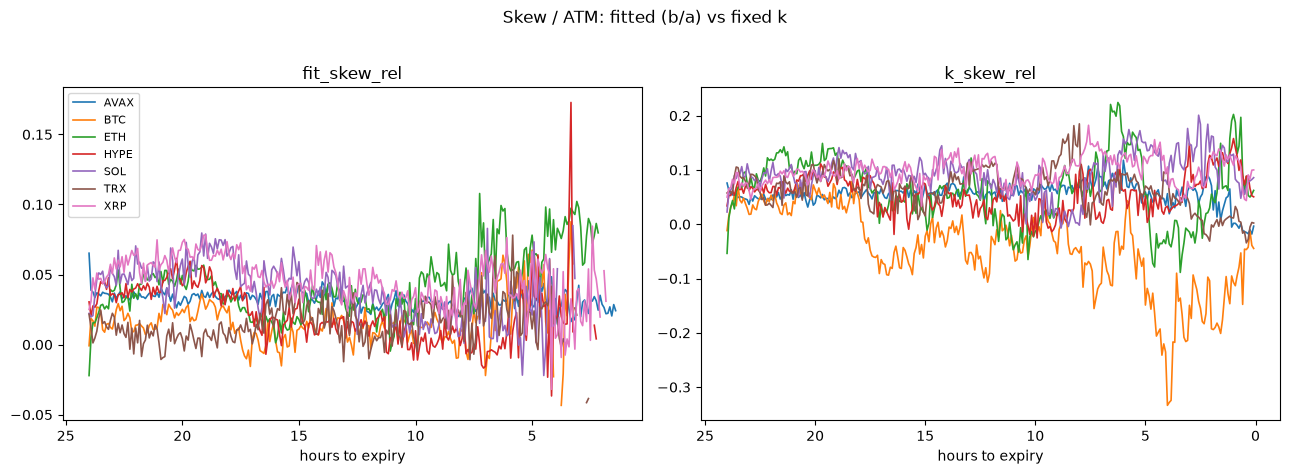

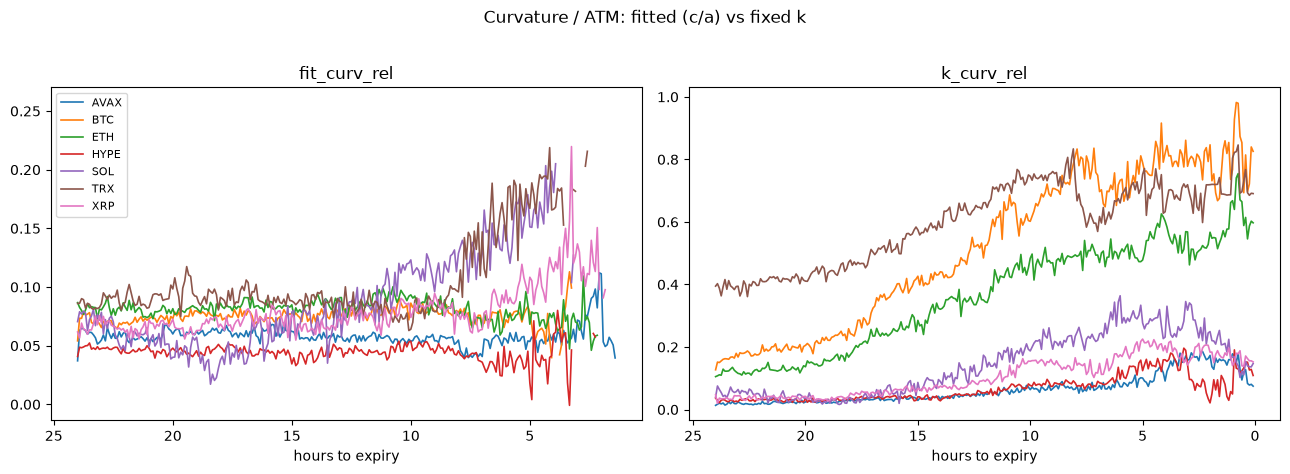

In [41]:
prim_fits = fits.merge(
    features[["state_id", "primary_option_family_id", "underlying", "session_id", "state_time",
              "minutes_to_expiry", "tte_bucket", "option_iv_atm_forward", "option_skew_025",
              "option_curvature_025", "rr_25d", "core_smile_usable"]],
    left_on=["state_id", "option_family_id"], right_on=["state_id", "primary_option_family_id"], how="right",
)
prim_fits.loc[~prim_fits["fit_ok"].fillna(False).astype(bool), ["fit_a", "fit_b", "fit_c"]] = np.nan
prim_fits["fit_skew_rel"] = prim_fits["fit_b"] / prim_fits["fit_a"]
prim_fits["fit_curv_rel"] = prim_fits["fit_c"] / prim_fits["fit_a"]
prim_fits["k_skew_rel"] = prim_fits["option_skew_025"] / prim_fits["option_iv_atm_forward"]
prim_fits["k_curv_rel"] = prim_fits["option_curvature_025"] / prim_fits["option_iv_atm_forward"]

# 1) coverage
cov = prim_fits.groupby(["underlying", "tte_bucket"], observed=True).agg(
    fit_pct=("fit_a", lambda s: 100 * s.notna().mean()),
    fixed_k_core_pct=("core_smile_usable", lambda s: 100 * s.fillna(False).astype(bool).mean()),
    delta25_pct=("rr_25d", lambda s: 100 * s.notna().mean()),
    median_quotes=("n", "median"),
    median_wrmse=("fit_wrmse", "median"),
).round(2)
display(cov)
print("Median |fit a − pipeline ATM IV| (IV points):",
      round(float((prim_fits["fit_a"] - prim_fits["option_iv_atm_forward"]).abs().median()), 3))

# 2) clock dependence
eta_rows = []
for asset, g in prim_fits.groupby("underlying"):
    for label, kc, fcol in [("skew / ATM", "k_skew_rel", "fit_skew_rel"),
                            ("curvature / ATM", "k_curv_rel", "fit_curv_rel")]:
        both = g.dropna(subset=[kc, fcol])
        eta_rows.append({"underlying": asset, "measure": label, "n_both": len(both),
                         "eta2_fixed_k": eta_squared(both, kc), "eta2_fit": eta_squared(both, fcol)})
fit_eta = pd.DataFrame(eta_rows)
display(fit_eta.round(3))

# 3) noise in 5m changes
prim_fits = prim_fits.sort_values(["underlying", "state_time"])
for col in ["fit_a", "fit_b", "fit_c"]:
    prev = prim_fits.groupby("underlying")[col].shift(1)
    contiguous = (
        (prim_fits["state_time"] - prim_fits.groupby("underlying")["state_time"].shift(1) == pd.Timedelta(minutes=5))
        & (prim_fits["session_id"] == prim_fits.groupby("underlying")["session_id"].shift(1))
    )
    prim_fits[f"d_{col}_5m"] = (prim_fits[col] - prev).where(contiguous)
fit_noise = pd.concat(
    [lag1_noise(prim_fits, c) for c in ["d_fit_a_5m", "d_fit_b_5m", "d_fit_c_5m"]]
    + [lag1_noise(features, "atm_iv_change_5m"), lag1_noise(features, "skew_025_change_5m")],
    ignore_index=True,
)
display(fit_noise.pivot(index="underlying", columns="feature", values="rho1").round(3))

# 4) family agreement of fitted parameters (BTC, ETH)
fam_fit = fits.merge(
    fam2[["state_id", "underlying", "session_id", "state_time", "family", "instrument_type"]]
    .assign(option_family_id=lambda d: np.where(d["family"] == "linear",
                                                d["underlying"] + "|linear|USDC|USDC",
                                                d["underlying"] + "|reversed|" + d["underlying"] + "|" + d["underlying"])),
    on=["state_id", "option_family_id"], how="inner",
)
fam_fit.loc[~fam_fit["fit_ok"].fillna(False).astype(bool), ["fit_a", "fit_b"]] = np.nan
fam_fit = fam_fit.sort_values(["option_family_id", "state_time"])
fit_agree = []
for lag, label in [(1, "5m"), (3, "15m")]:
    for col in ["fit_a", "fit_b"]:
        g = fam_fit.groupby("option_family_id")
        ok_lag = (
            (fam_fit["state_time"] - g["state_time"].shift(lag) == pd.Timedelta(minutes=5 * lag))
            & (fam_fit["session_id"] == g["session_id"].shift(lag))
        )
        fam_fit[f"d_{col}_{label}"] = (fam_fit[col] - g[col].shift(lag)).where(ok_lag)
        w = fam_fit.pivot_table(index=["underlying", "state_id"], columns="family",
                                values=f"d_{col}_{label}", aggfunc="first").dropna()
        for asset, gg in w.groupby(level="underlying"):
            if {"linear", "inverse"}.issubset(gg.columns) and len(gg) > 30:
                fit_agree.append({"underlying": asset, "parameter": col, "horizon": label, "n": len(gg),
                                  "spearman": gg["linear"].corr(gg["inverse"], method="spearman")})
fit_family_agreement = pd.DataFrame(fit_agree)
display(fit_family_agreement.pivot_table(index=["underlying", "parameter"], columns="horizon", values="spearman").round(3)
        if not fit_family_agreement.empty else fit_family_agreement)

plot_median_by_tte(prim_fits, ["fit_skew_rel", "k_skew_rel"], "Skew / ATM: fitted (b/a) vs fixed k")
plot_median_by_tte(prim_fits, ["fit_curv_rel", "k_curv_rel"], "Curvature / ATM: fitted (c/a) vs fixed k")

# Part I — Research Handoff

## 22. Interpretation checklist

Answer these before Notebook 04:

1. **B1:** how many valid option states does the futures gate remove, and on which dates? Is decoupling surface eligibility from the futures stream justified?
2. **A2:** how far does the ±2.5% node travel in $z$ through the session, and for which assets is it beyond 3σ for most of the day?
3. **A2:** do $z$-space skew and curvature have materially lower $\eta^2$ than the fixed-$k$ versions? For which assets?
4. **A2 trade-off:** where does the $z$-grid lose coverage or need large spans (near expiry, coarse strike grids)?
5. **B2:** what share of core nodes is mark-sourced, by asset and time to expiry? Above what share should an asset's option features be treated as Deribit-model information rather than market information?
6. **B2:** are 5-minute changes across a source switch materially noisier than same-source changes?
7. **B4:** do levels or changes break inside the settlement window?
8. Which option features are persistent enough to be structural, and which behave as innovations?
9. Do the BTC/ETH linear and inverse families agree?
10. Is any of this based on too little history (16 sessions) to support a production decision?
11. **Pipeline v0.2:** what share of 5m core changes is now withheld by source switches, and how many option states did decoupling from the futures gate recover?
12. **Noise:** after source-consistent changes, what noise-to-signal ratio remains in 5m ATM / skew changes? Should structural option dynamics use 15m–1h horizons instead?
13. **Spikes and families:** are the BTC/ETH ATM spikes real? Do families agree once measured robustly, and at which horizon?
14. **Fitted smile (A2):** does the quadratic $z$-fit beat fixed-$k$ and delta on coverage, clock dependence, noise and family agreement? Where does it fail (near expiry, TRX)?

Source-consistent changes (B2), futures decoupling (B1) and the settlement flag (B4) are implemented in surfaces v0.2 / option features v0.2.0. **The representation decision (A2: fixed-$k$, delta or fitted $z$-smile) is not made here**; it is a `src/` change to be proposed with Sections 20–21 as evidence.

In [42]:
surface_distribution_report = {
    "futures_gate_loss": gate,
    "availability_by_tte": availability.reset_index(),
    "level_by_asset": level_by_asset,
    "z_of_k025_by_tte": z_table.reset_index(),
    "eta2_fixed": eta_fixed.reset_index(),
    "core_mark_share_by_tte": mark_share.reset_index(),
    "source_switch_changes": switch_summary.reset_index(),
    "z_grid_coverage": z_cov.reset_index(),
    "stationarity_k_vs_z": stationarity,
    "settlement_window": settlement,
    "option_acf": option_acf,
    "family_comparison": family_comparison,
    "noise_ratio": noise_tab,
    "family_agreement_robust": family_agreement,
    "fit_coverage": cov.reset_index(),
    "fit_eta2": fit_eta,
    "fit_noise": fit_noise,
    "fit_family_agreement": fit_family_agreement,
}
print("Surface-distribution report sections:")
for name, frame in surface_distribution_report.items():
    print(f"  {name:<26} {len(frame):>8,} rows")

Surface-distribution report sections:
  futures_gate_loss               112 rows
  availability_by_tte              49 rows
  level_by_asset                  105 rows
  z_of_k025_by_tte                  7 rows
  eta2_fixed                       15 rows
  core_mark_share_by_tte            7 rows
  source_switch_changes            28 rows
  z_grid_coverage                  49 rows
  stationarity_k_vs_z              28 rows
  settlement_window                63 rows
  option_acf                    1,344 rows
  family_comparison                 2 rows
  noise_ratio                      28 rows
  family_agreement_robust          37 rows
  fit_coverage                     49 rows
  fit_eta2                         14 rows
  fit_noise                        35 rows
  fit_family_agreement              8 rows


## 23. Close the read-only connection

In [43]:
con.close()
print("DuckDB connection closed.")

DuckDB connection closed.
